# Notebook 05: Multi-Signal Retraining Policy and Champion-Challenger Evaluation

**Project:** Design and Evaluation of a Governed Multi-Signal Drift-Aware Intervention Policy under Delayed Labels: A Google Cloud MLOps Prototype 

**Author:** Sahar Imani  
**Notebook:** 5 of 5

This notebook turns monthly monitoring evidence into decisions and then evaluates the decisions. The object of study is the policy, not the drift.

Four policies run over the same 2014–2016 stream:

- **Policy A** — naive feature-drift requests. Every feature-drift trigger raises a retraining request, with no corroboration, persistence, gate or cooldown. Its output is a count of requests, never deployments.
- **Policy B** — governed feature-drift-only. Feature drift is the only trigger and acts immediately at `monitor_month`, but every eligible trigger trains a full challenger and goes through the same validation, gate, hold-off and cooldown as Policy C.
- **Policy C** — governed multi-signal. An evidence hierarchy, delayed outcome-aware corroboration, champion-specific persistence, and a recalibrate-versus-retrain fork, on the same governance machinery as Policy B.
- **Policy D** — governed six-month calendar candidate evaluation. No monitoring signal of any kind is consulted. Its purpose is diagnostic: because feature drift fires in almost every month, Policy B may be timed by its cooldown rather than by its trigger, and Policy D measures how much decision value the feature-drift trigger adds over a fixed schedule.


### Design principles

**The loop is closed.** Each cohort is scored by the champion actually deployed that month, the probabilities are frozen, and every model-dependent signal (prediction drift, calibration, Brier, log loss, Receiver Operating Characteristic Area Under the Curve (ROC AUC), score-conditional outcome drift) is computed from those frozen scores and attributed to the champion that produced them. Notebook 04's fixed-reference monitoring is reused only for the portfolio-level signals that do not depend on the deployed model.

**The label delay binds.** Delayed evidence for cohort `m` is usable only from `decision_month = m + label_delay_months`. Immediate signals stay usable at `monitor_month`, which is the apparent advantage of the naive baseline.

**No future information enters a decision.** The gate at decision month `d` uses only labels available by `d`.

**Drift does not mean automatic retraining.** The thresholds below are operational study choices fixed before this run. The literature supports the choice of metric, not the specific cut-off.

**What "better" is taken to mean.** Not more retraining, and not fewer alerts. The comparison is a trade-off between intervention burden, the number of deployed model changes, and managed probability reliability, judged against practical margins declared before the results were seen. A policy that raises fewer alerts but fits the same number of candidates has not saved any work, and the results below are reported.

## 1. Loading Monitoring Artefacts and the Starting Champion

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

In [2]:
# Same directories as Notebooks 02, 03 and 04
processed_dir = "../data/processed"
baselines_dir = "../artifacts/baselines"
models_dir = "../artifacts/models"
monitoring_dir = "../artifacts/monitoring"
inference_dir = "../data/inference"
policy_dir = "../artifacts/retraining_policy"

os.makedirs(policy_dir, exist_ok=True)

print("Policy output directory:", policy_dir)

Policy output directory: ../artifacts/retraining_policy


In [3]:
# Monthly monitoring evidence from Notebook 04
# These remain the fixed-reference descriptive monitoring of the original champion
monthly_counts = pd.read_csv(f"{monitoring_dir}/monthly_counts.csv")

monthly_feature_drift_summary = pd.read_csv(f"{monitoring_dir}/monthly_feature_drift_summary.csv")
monthly_feature_drift_summary_excl_policy = pd.read_csv(
    f"{monitoring_dir}/monthly_feature_drift_summary_excl_policy.csv")

monthly_prediction_drift = pd.read_csv(f"{monitoring_dir}/monthly_prediction_drift.csv")

monthly_target_drift = pd.read_csv(f"{monitoring_dir}/monthly_target_drift.csv")
monthly_concept_drift = pd.read_csv(f"{monitoring_dir}/monthly_score_conditional_outcome_drift.csv")
monthly_delayed_performance = pd.read_csv(f"{monitoring_dir}/monthly_delayed_performance.csv")
monthly_data_quality = pd.read_csv(f"{monitoring_dir}/monthly_data_quality.csv")

with open(f"{monitoring_dir}/monitoring_threshold_metadata.json") as f:
    monitoring_metadata = json.load(f)

print("Monitoring tables loaded.")
print("Monitoring months:", monthly_counts.shape[0])

Monitoring tables loaded.
Monitoring months: 36


In [4]:
# Starting champion and its baselines
champion_model = joblib.load(f"{models_dir}/champion_xgboost_model.joblib")

with open(f"{models_dir}/champion_model_metadata.json") as f:
    champion_model_metadata = json.load(f)

champion_feature_cols = pd.read_csv(f"{baselines_dir}/champion_feature_cols.csv")["feature"].tolist()
monitoring_categorical_cols = pd.read_csv(f"{baselines_dir}/monitoring_categorical_cols.csv")["feature"].tolist()
champion_performance = pd.read_csv(f"{baselines_dir}/champion_performance.csv")
concept_drift_baseline = pd.read_csv(f"{baselines_dir}/concept_drift_baseline.csv")

# Score-bin edges and the 2013 calibration cohort scored by the original champion
# They define the original champion's monitoring reference exactly as in Notebook 04
score_edges = joblib.load(f"{baselines_dir}/prediction_drift_score_bin_edges.joblib")
calibration_scored_df = pd.read_parquet(f"{inference_dir}/calibration_2013_scored.parquet")

print("Starting champion:", champion_model_metadata["champion_model_name"])
print("Champion feature count:", len(champion_feature_cols))
print("Calibration reference rows:", calibration_scored_df.shape[0])

display(champion_performance.round(4))

[HAMI-core Msg(1361:140356640017728:libvgpu.c:839)]: Initializing.....
[HAMI-core Msg(1361:140356640017728:libvgpu.c:855)]: Initialized


Starting champion: keep_sub_grade_only
Champion feature count: 67
Calibration reference rows: 29740


,dataset,rows,actual_bad_loan_rate,mean_predicted_probability,roc_auc,average_precision,log_loss,brier_score,calibration_gap
0,train,105074,0.1566,0.1566,0.7509,0.3747,0.3802,0.1170,0.0000
1,calibration,29740,0.1536,0.1511,0.6990,0.2812,0.3964,0.1216,0.0025
2,simulation,1041560,0.1925,0.1584,0.7085,0.3568,0.4507,0.1432,0.0342


In [5]:
# Load processed datasets and scored inference output
historical_df = pd.read_parquet(f"{processed_dir}/historical_2013_clean.parquet")
simulation_df = pd.read_parquet(f"{processed_dir}/simulation_2014_2016_clean.parquet")
simulation_scored_df = pd.read_parquet(f"{inference_dir}/simulation_2014_2016_scored.parquet")

target_col = "target_bad_loan"
prediction_col = "predicted_bad_loan_probability"

if len(simulation_df) != len(simulation_scored_df):
    raise ValueError("simulation_df and simulation_scored_df have different row counts.")

In [6]:
# Attach champion predictions and monitoring months
simulation_df = simulation_df.copy()
simulation_df[prediction_col] = simulation_scored_df[prediction_col].values
simulation_df["monitor_month"] = pd.to_datetime(simulation_df["issue_d"]).dt.to_period("M").astype(str)

all_monitor_months = sorted(simulation_df["monitor_month"].unique())
month_frames = {month: frame for month, frame in simulation_df.groupby("monitor_month")}

In [7]:
# Record the historical reference interval
historical_issue_months = pd.to_datetime(historical_df["issue_d"]).dt.to_period("M")
historical_start_month = str(historical_issue_months.min())
historical_end_month = str(historical_issue_months.max())

print("Historical shape:", historical_df.shape)
print("Historical interval:", historical_start_month, "to", historical_end_month)
print("Simulation shape:", simulation_df.shape)
print("Monitoring months in the simulation stream:", len(all_monitor_months))

Historical shape: (134814, 73)
Historical interval: 2013-01 to 2013-12
Simulation shape: (1041560, 75)
Monitoring months in the simulation stream: 36


In [8]:
# Reuse Notebook 04's assumptions rather than redeclaring them
label_delay_months = int(monitoring_metadata["label_delay_months"])
platform_policy_features = monitoring_metadata["platform_policy_features"]
signal_roles = monitoring_metadata["signal_roles"]

# Classification thresholds shared with Notebook 04. The same thresholds are applied to every
# champion, so evidence levels stay comparable before and after a promotion
prediction_jsd_moderate_band = float(monitoring_metadata["prediction_jsd_moderate_band"])
concept_moderate_threshold = float(monitoring_metadata["concept_moderate_threshold"])
concept_high_threshold = float(monitoring_metadata["concept_high_threshold"])
concept_localisation_threshold = float(monitoring_metadata["concept_localisation_threshold"])
calibration_gap_moderate_threshold = float(monitoring_metadata["calibration_gap_moderate_threshold"])
calibration_gap_high_threshold = float(monitoring_metadata["calibration_gap_high_threshold"])
brier_moderate_threshold = float(monitoring_metadata["brier_moderate_threshold"])
brier_high_threshold = float(monitoring_metadata["brier_high_threshold"])
auc_drop_moderate_threshold = float(monitoring_metadata["auc_drop_moderate_threshold"])
auc_drop_high_threshold = float(monitoring_metadata["auc_drop_high_threshold"])

concept_min_bin_rows = 100

In [9]:
print("Label delay (months):", label_delay_months)
print("Platform-policy features:", platform_policy_features)
print("\nSignal roles inherited from Notebook 04:")
for signal_name, role in signal_roles.items():
    print(f"  {signal_name:35s} -> {role}")

Label delay (months): 5
Platform-policy features: ['initial_list_status']

Signal roles inherited from Notebook 04:
  feature_drift                       -> early_warning_only
  prediction_drift                    -> early_warning_only
  data_quality                        -> governance_corroborating_only
  target_drift                        -> corroborating_only
  score_conditional_outcome_drift     -> strong_delayed_evidence
  delayed_performance_drift           -> strongest_delayed_evidence


### Artefact checks

In [10]:
# Define the expected monthly coverage
expected_months = sorted(monthly_counts["monitor_month"].unique())
expected_month_count = len(expected_months)

monitoring_tables = {"monthly_counts": monthly_counts,
                     "monthly_feature_drift_summary": monthly_feature_drift_summary,
                     "monthly_feature_drift_summary_excl_policy": monthly_feature_drift_summary_excl_policy,
                     "monthly_prediction_drift": monthly_prediction_drift,
                     "monthly_target_drift": monthly_target_drift,
                     "monthly_concept_drift": monthly_concept_drift,
                     "monthly_delayed_performance": monthly_delayed_performance,
                     "monthly_data_quality": monthly_data_quality}

delayed_tables = ["monthly_target_drift",
                  "monthly_concept_drift",
                  "monthly_delayed_performance"]

In [11]:
# Check that every monitoring table covers the same months
for table_name, table in monitoring_tables.items():
    assert table.shape[0] == expected_month_count, f"{table_name} has {table.shape[0]} rows."
    assert sorted(table["monitor_month"].unique()) == expected_months, f"{table_name} covers different months."
    assert table["monitor_month"].is_unique, f"{table_name} has duplicate months."

assert expected_months == all_monitor_months, "Monitoring months differ from the simulation stream."

In [12]:
# Check that delayed tables carry the correct decision month
for table_name in delayed_tables:
    table = monitoring_tables[table_name]

    for required_col in ["decision_month", "delayed_signal_usable", "label_delay_months"]:
        assert required_col in table.columns, f"{table_name} is missing {required_col}."

    implied_delay = (table["decision_month"].apply(lambda x: pd.Period(x, freq="M")) - table["monitor_month"].apply(lambda x: pd.Period(x, freq="M"))).apply(lambda x: x.n)

    assert (implied_delay == label_delay_months).all(), f"{table_name} decision_month mismatch."

print("Monitoring months:", expected_month_count, "|", expected_months[0], "to", expected_months[-1])
print("Delayed tables carry decision_month with a", label_delay_months, "month delay.")
print("All artefact checks passed.")

Monitoring months: 36 | 2014-01 to 2016-12
Delayed tables carry decision_month with a 5 month delay.
All artefact checks passed.


## 2. Portfolio-Level Signals and Reference Evidence

One row per monitoring month. Feature drift, target-rate drift and data quality are portfolio-level signals that do not depend on which model is deployed, so every policy reuses them directly. Prediction drift, score-conditional outcome drift and performance are model-dependent; the columns here describe the original champion only, while the engine below recomputes them for whichever champion actually scored each cohort.

In [13]:
# Start with one row per monitoring month
signal_matrix = monthly_counts[["monitor_month", "rows", "actual_bad_loan_rate", "mean_predicted_probability"]].copy()

In [14]:
# Add immediately available monitoring signals
signal_matrix = signal_matrix.merge(monthly_feature_drift_summary[["monitor_month", "max_feature_psi", "supported_feature_drift_count",
                                   "feature_drift_trigger", "feature_drift_trigger_excl_policy"]], on="monitor_month", how="left")

signal_matrix = signal_matrix.merge(monthly_prediction_drift[["monitor_month", "prediction_jsd", "prediction_drift_trigger"]],
                                    on="monitor_month", how="left")

signal_matrix = signal_matrix.merge(monthly_data_quality[["monitor_month", "unseen_category_count",
                                                          "mean_feature_missing_rate", "data_quality_flag"]], on="monitor_month", how="left")

In [15]:
# Add delayed outcome-aware signals
signal_matrix = signal_matrix.merge(monthly_target_drift[["monitor_month", "decision_month",
                                                          "target_rate_change", "target_drift_level",
                                                          "target_drift_trigger"]],
                                    on="monitor_month", how="left")

signal_matrix = signal_matrix.merge(monthly_concept_drift[["monitor_month", "score_bin_mean_absolute_shift",
                                                           "score_bin_signed_shift", "concept_shift_type",
                                                           "delayed_concept_drift_level",
                                                           "delayed_concept_drift_trigger"]],
                                    on="monitor_month", how="left")

signal_matrix = signal_matrix.merge(monthly_delayed_performance[["monitor_month", "calibration_gap",
                                                                 "absolute_calibration_gap", "brier_score",
                                                                 "brier_score_change", "roc_auc", "auc_drop",
                                                                 "delayed_performance_drift_level",
                                                                 "delayed_performance_trigger"]],
                                    on="monitor_month", how="left")

# Mark delayed deterioration for each monitoring cohort
signal_matrix["delayed_deterioration"] = (signal_matrix["delayed_performance_trigger"] | signal_matrix["delayed_concept_drift_trigger"])
 
monthly_signal_matrix = signal_matrix.sort_values("monitor_month").reset_index(drop=True)
portfolio_lookup = monthly_signal_matrix.set_index("monitor_month")

print("Monthly signal matrix shape:", monthly_signal_matrix.shape)

Monthly signal matrix shape: (36, 31)


In [16]:
# Check the monthly signal matrix
assert monthly_signal_matrix.shape[0] == expected_month_count, "Wrong number of months."
assert monthly_signal_matrix["monitor_month"].is_unique, "Duplicate monitoring months."
assert monthly_signal_matrix["decision_month"].notna().all(), "Missing decision months."

In [17]:
# Summarise how often each signal fires
signal_frequency = pd.DataFrame([{"signal": "feature_drift (all features)",
                                  "role": signal_roles["feature_drift"],
                                  "triggered_months": int(monthly_signal_matrix["feature_drift_trigger"].sum())},
                                 {"signal": "feature_drift (excl. platform policy)",
                                  "role": "sensitivity_check",
                                  "triggered_months": int(monthly_signal_matrix["feature_drift_trigger_excl_policy"].sum())},
                                 {"signal": "prediction_drift (original champion)",
                                  "role": signal_roles["prediction_drift"],
                                  "triggered_months": int(monthly_signal_matrix["prediction_drift_trigger"].sum())},
                                 {"signal": "data_quality",
                                  "role": signal_roles["data_quality"],
                                  "triggered_months": int(monthly_signal_matrix["data_quality_flag"].sum())},
                                 {"signal": "target_drift",
                                  "role": signal_roles["target_drift"],
                                  "triggered_months": int(monthly_signal_matrix["target_drift_trigger"].sum())},
                                 {"signal": "score_conditional_outcome_drift (original champion)",
                                  "role": signal_roles["score_conditional_outcome_drift"],
                                  "triggered_months": int(monthly_signal_matrix["delayed_concept_drift_trigger"].sum())},
                                 {"signal": "delayed_performance_drift (original champion)",
                                  "role": signal_roles["delayed_performance_drift"],
                                  "triggered_months": int(monthly_signal_matrix["delayed_performance_trigger"].sum())}])

signal_frequency["percentage_of_months"] = (signal_frequency["triggered_months"] / expected_month_count * 100).round(1)

display(signal_frequency)

print("Months with delayed outcome-aware deterioration of the original champion:",
      int(monthly_signal_matrix["delayed_deterioration"].sum()), "of", expected_month_count)

,signal,role,triggered_months,percentage_of_months
0,feature_drift (all features),early_warning_only,33,91.7
1,feature_drift (excl. platform policy),sensitivity_check,27,75.0
2,prediction_drift (original champion),early_warning_only,0,0.0
3,data_quality,governance_corroborating_only,10,27.8
4,target_drift,corroborating_only,32,88.9
5,score_conditional_outcome_drift (original cham...,strong_delayed_evidence,23,63.9
6,delayed_performance_drift (original champion),strongest_delayed_evidence,26,72.2


Months with delayed outcome-aware deterioration of the original champion: 27 of 36


Most signals fire in a large share of months, so simply combining them with OR would trigger almost continuously. Selectivity therefore comes from the policy structure. Which signals may trigger action, how evidence is corroborated and persisted, whether delayed evidence is still relevant to the current champion, and whether a candidate passes the deployment gate.

## 3. Policy A: Naive Feature-Drift Request Baseline

Policy A is deliberately naive. Every feature-drift trigger raises a retraining request, with no corroboration, persistence, cooldown or gate, and it acts at `monitor_month` because it needs no labels.

Its output is therefore a count of **requests**, not deployments. A request only means that the feature-drift condition was met and that further action could be considered. The PSI bands of 0.10 and 0.25 are used here as the operational thresholds.

In [18]:
# Create naive feature-drift retraining requests
policy_a_requests = monthly_signal_matrix[["monitor_month", "rows", "max_feature_psi",
                                           "supported_feature_drift_count", "feature_drift_trigger",
                                           "feature_drift_trigger_excl_policy",
                                           "delayed_deterioration"]].copy()

policy_a_requests["retraining_request"] = policy_a_requests["feature_drift_trigger"]
policy_a_requests["retraining_request_excl_policy"] = policy_a_requests["feature_drift_trigger_excl_policy"]

# Flag requests without delayed deterioration
policy_a_requests["request_without_deterioration"] = (policy_a_requests["retraining_request"] & ~policy_a_requests["delayed_deterioration"])

In [19]:
# Summarise the naive retraining policies
policy_a_summary = pd.DataFrame([{"baseline_policy_name": "feature_drift_only_all_features",
                                  "retraining_requests": int(policy_a_requests["retraining_request"].sum()),
                                  "percentage_of_months": round(int(policy_a_requests["retraining_request"].sum()) / expected_month_count * 100, 1),
                                  "requests_without_delayed_deterioration": int(policy_a_requests["request_without_deterioration"].sum())},
                                 {"baseline_policy_name": "feature_drift_only_excluding_platform_policy",
                                  "retraining_requests": int(policy_a_requests["retraining_request_excl_policy"].sum()),
                                  "percentage_of_months": round(int(policy_a_requests["retraining_request_excl_policy"].sum()) /expected_month_count * 100, 1),
                                  "requests_without_delayed_deterioration":int((policy_a_requests["retraining_request_excl_policy"] &
                                                                                ~policy_a_requests["delayed_deterioration"]).sum())}])

display(policy_a_summary)

display(policy_a_requests[["monitor_month", "max_feature_psi", "supported_feature_drift_count",
                           "retraining_request", "delayed_deterioration",
                           "request_without_deterioration"]].head(12).round(4))

,baseline_policy_name,retraining_requests,percentage_of_months,requests_without_delayed_deterioration
0,feature_drift_only_all_features,33,91.7,6
1,feature_drift_only_excluding_platform_policy,27,75.0,6


,monitor_month,max_feature_psi,supported_feature_drift_count,retraining_request,delayed_deterioration,request_without_deterioration
0,2014-01,0.1666,1,False,False,False
1,2014-02,0.1528,2,False,False,False
2,2014-03,0.3654,4,True,False,True
3,2014-04,0.3057,4,True,False,True
4,2014-05,0.3291,4,True,False,True
5,2014-06,0.5781,3,True,True,False
6,2014-07,0.5098,4,True,False,True
7,2014-08,0.2746,3,True,False,True
8,2014-09,0.2370,3,False,False,False
9,2014-10,0.4255,3,True,True,False


Removing `initial_list_status` reduces the number of requests from 33 to 27. This feature mainly reflects Lending Club's listing process rather than borrower risk, so some of the feature drift is related to platform changes. The all-features version is kept as the main baseline. The excluding version is used as a sensitivity check.

The main issue with Policy A is not that the requests are usually wrong, but that they are frequent and do not say what action should follow. Feature drift alone cannot distinguish between recalibration, retraining, or taking no action.

## 4. Study Settings: Deployment Gates, Action Fork and Governance

The gate settings differ by candidate type because the two actions have different purposes. A full challenger must improve both Brier score and calibration gap. Recalibration is focused on correcting calibration, while Brier score, log loss and ROC-AUC are kept within defined tolerances.

The sensitivity analysis repeats the evaluation under permissive, primary and strict gate settings.

In [20]:
# Gates differ by action, since the actions differ in purpose
# Challenger retraining must improve both probability-reliability metrics
# Recalibration must improve calibration while remaining non-inferior elsewhere
GATE_PRIMARY = {"name": "primary",
                "challenger_brier_improvement_min": 0.0005,
                "challenger_calibration_gap_improvement_min": 0.002,
                "recalibration_brier_tolerance": 0.0002,
                "recalibration_calibration_gap_improvement_min": 0.002,
                "log_loss_tolerance": 0.001,
                "auc_drop_guardrail": 0.01,
                "min_validation_rows": 10000}

GATE_PERMISSIVE = {**GATE_PRIMARY,
                   "name": "permissive",
                   "challenger_brier_improvement_min": 1e-12,
                   "challenger_calibration_gap_improvement_min": 1e-12,
                   "recalibration_brier_tolerance": 0.001,
                   "recalibration_calibration_gap_improvement_min": 1e-12}

GATE_STRICT = {**GATE_PRIMARY,
               "name": "strict",
               "challenger_brier_improvement_min": 0.001,
               "challenger_calibration_gap_improvement_min": 0.005,
               "recalibration_brier_tolerance": 0.0,
               "recalibration_calibration_gap_improvement_min": 0.005}

In [21]:
# Recalibration-versus-retraining fork settings (study choices, not universal standards)
AUC_DROP_FORK_THRESHOLD = 0.02
CALIBRATION_SLOPE_DEVIATION = 0.15
RESIDUAL_BIN_SHIFT_THRESHOLD = 0.01

# Governance settings shared by both governed policies
deployment_cooldown_months = 6
candidate_evaluation_holdoff_months = 2
validation_window_months = 3
persistence_cohorts = 2

# Policy D schedule: the calendar interval is declared here, before any policy is run
calendar_interval_months = 6

# Practical non-inferiority margins used only for final policy-versus-policy reporting
# The same margins apply to Policy C versus Policy B and to Policy C versus Policy D
# They are declared before the runs and do not determine deployment
NONINFERIORITY_MARGINS = {"brier_score": 0.001, "absolute_calibration_gap": 0.003, "roc_auc": 0.01}

BOOTSTRAP_RESAMPLES = 500
BOOTSTRAP_BLOCK_MONTHS = 3
BOOTSTRAP_BLOCK_LENGTHS = [2, 3, 6]

In [22]:
print("Primary challenger gate:", {k: v for k, v in GATE_PRIMARY.items() if k.startswith("challenger_")})

print("Primary recalibration gate:", {k: v for k, v in GATE_PRIMARY.items() if k.startswith("recalibration_")})

print("Common guardrails:", {k: GATE_PRIMARY[k] for k in ["log_loss_tolerance", "auc_drop_guardrail","min_validation_rows"]})

print("Fork thresholds:", AUC_DROP_FORK_THRESHOLD, CALIBRATION_SLOPE_DEVIATION, RESIDUAL_BIN_SHIFT_THRESHOLD)
print("Deployment cooldown (months):", deployment_cooldown_months)
print("Candidate evaluation hold-off (months):", candidate_evaluation_holdoff_months)
print("Validation window (months):", validation_window_months)
print("Persistence requirement (consecutive mature cohorts):", persistence_cohorts)
print("Policy D calendar interval (months):", calendar_interval_months)
print("Bootstrap block lengths tested (months):", BOOTSTRAP_BLOCK_LENGTHS,
      "| primary:", BOOTSTRAP_BLOCK_MONTHS)

Primary challenger gate: {'challenger_brier_improvement_min': 0.0005, 'challenger_calibration_gap_improvement_min': 0.002}
Primary recalibration gate: {'recalibration_brier_tolerance': 0.0002, 'recalibration_calibration_gap_improvement_min': 0.002}
Common guardrails: {'log_loss_tolerance': 0.001, 'auc_drop_guardrail': 0.01, 'min_validation_rows': 10000}
Fork thresholds: 0.02 0.15 0.01
Deployment cooldown (months): 6
Candidate evaluation hold-off (months): 2
Validation window (months): 3
Persistence requirement (consecutive mature cohorts): 2
Policy D calendar interval (months): 6
Bootstrap block lengths tested (months): [2, 3, 6] | primary: 3


## 5. Chronological Data Availability

At each decision month `d`, only cohorts whose labels have become available can be used. The three most recent labelled months form the validation window, while earlier available data are kept for candidate training. Training and validation remain separate, and no labels from the decision month or later are allowed into the gate.

The three-month validation window keeps the evaluation focused on recent conditions while still leaving earlier data available for training.

In [23]:
# What is labelled and usable at each decision month
def get_available_labelled_months(decision_month, label_delay):
    latest_available = pd.Period(decision_month, freq="M") - label_delay
    return [m for m in all_monitor_months if pd.Period(m, freq="M") <= latest_available]

In [24]:
## Split available labelled months into training and validation windows
def split_training_and_validation(decision_month, label_delay, validation_window):
    available = get_available_labelled_months(decision_month, label_delay)

    if len(available) <= validation_window:
        return [], []

    return available[:-validation_window], available[-validation_window:]

Policy D follows the same label-availability rule, but its evaluation dates are fixed rather than triggered by drift. The first eligible evaluation month is September 2014, followed by six-month intervals through March 2017.

In [25]:
# Earliest decision month with a complete chronological training and validation window
def first_eligible_decision_month(label_delay, validation_window):
    calendar = pd.period_range(pd.Period(all_monitor_months[0], freq="M"),
                               pd.Period(all_monitor_months[-1], freq="M") + label_delay,
                               freq="M")

    for period in calendar:
        training_months, validation_months = split_training_and_validation(
            str(period), label_delay, validation_window)

        if len(training_months) > 0 and len(validation_months) == validation_window:
            return period

    return None

In [26]:
# Fixed calendar schedule used by Policy D, derived only from label availability
def build_calendar_schedule(label_delay, validation_window, interval):
    start = first_eligible_decision_month(label_delay, validation_window)

    if start is None:
        return []

    last = pd.Period(all_monitor_months[-1], freq="M") + label_delay

    return [str(period) for period in pd.period_range(start, last, freq="M")[::interval]]

In [27]:
# The schedule depends on label availability only, never on drift or on observed promotions
calendar_schedule_primary = build_calendar_schedule(label_delay_months, validation_window_months,
                                                    calendar_interval_months)

print("First eligible calendar evaluation month:",
      str(first_eligible_decision_month(label_delay_months, validation_window_months)))

print("Policy D calendar schedule:", calendar_schedule_primary)

assert calendar_schedule_primary, "Policy D has no eligible calendar evaluation month."

assert all((pd.Period(later, freq="M") - pd.Period(earlier, freq="M")).n == calendar_interval_months
           for earlier, later in zip(calendar_schedule_primary, calendar_schedule_primary[1:])), (
    "Policy D schedule is not a fixed calendar interval.")

First eligible calendar evaluation month: 2014-09
Policy D calendar schedule: ['2014-09', '2015-03', '2015-09', '2016-03', '2016-09', '2017-03']


In [28]:
# Include the immediate Policy B calendar and the delayed Policy C calendar
all_policy_decision_months = sorted(set(all_monitor_months) | set(monthly_signal_matrix["decision_month"].tolist()))

In [29]:
# Build the data-availability timeline for every policy decision month
availability_rows = []

for decision_month in all_policy_decision_months:
    training_months, validation_months = split_training_and_validation(
        decision_month, label_delay_months, validation_window_months)

    availability_rows.append({"decision_month": decision_month,
                              "latest_label_available_month":
                                  str(pd.Period(decision_month, freq="M") - label_delay_months),
                              "training_months": len(training_months),
                              "simulation_training_start": training_months[0] if training_months else "none",
                              "simulation_training_end": training_months[-1] if training_months else "none",
                              "challenger_effective_start": historical_start_month if training_months else "none",
                              "challenger_effective_end": training_months[-1] if training_months else "none",
                              "validation_start": validation_months[0] if validation_months else "none",
                              "validation_end": validation_months[-1] if validation_months else "none"})

data_availability_timeline = pd.DataFrame(availability_rows)

display(data_availability_timeline.head(10))
display(data_availability_timeline.tail(10))

,decision_month,latest_label_available_month,training_months,simulation_training_start,simulation_training_end,challenger_effective_start,challenger_effective_end,validation_start,validation_end
0,2014-01,2013-08,0,none,none,none,none,none,none
1,2014-02,2013-09,0,none,none,none,none,none,none
2,2014-03,2013-10,0,none,none,none,none,none,none
3,2014-04,2013-11,0,none,none,none,none,none,none
4,2014-05,2013-12,0,none,none,none,none,none,none
5,2014-06,2014-01,0,none,none,none,none,none,none
6,2014-07,2014-02,0,none,none,none,none,none,none
7,2014-08,2014-03,0,none,none,none,none,none,none
8,2014-09,2014-04,1,2014-01,2014-01,2013-01,2014-01,2014-02,2014-04
9,2014-10,2014-05,2,2014-01,2014-02,2013-01,2014-02,2014-03,2014-05


,decision_month,latest_label_available_month,training_months,simulation_training_start,simulation_training_end,challenger_effective_start,challenger_effective_end,validation_start,validation_end
31,2016-08,2016-03,24,2014-01,2015-12,2013-01,2015-12,2016-01,2016-03
32,2016-09,2016-04,25,2014-01,2016-01,2013-01,2016-01,2016-02,2016-04
33,2016-10,2016-05,26,2014-01,2016-02,2013-01,2016-02,2016-03,2016-05
34,2016-11,2016-06,27,2014-01,2016-03,2013-01,2016-03,2016-04,2016-06
35,2016-12,2016-07,28,2014-01,2016-04,2013-01,2016-04,2016-05,2016-07
36,2017-01,2016-08,29,2014-01,2016-05,2013-01,2016-05,2016-06,2016-08
37,2017-02,2016-09,30,2014-01,2016-06,2013-01,2016-06,2016-07,2016-09
38,2017-03,2016-10,31,2014-01,2016-07,2013-01,2016-07,2016-08,2016-10
39,2017-04,2016-11,32,2014-01,2016-08,2013-01,2016-08,2016-09,2016-11
40,2017-05,2016-12,33,2014-01,2016-09,2013-01,2016-09,2016-10,2016-12


In [30]:
# Prove no future labels can reach a decision
for decision_month in all_policy_decision_months:
    training_months, validation_months = split_training_and_validation(
        decision_month, label_delay_months, validation_window_months)

    if len(training_months) == 0 or len(validation_months) == 0:
        continue

    latest_label_month = pd.Period(decision_month, freq="M") - label_delay_months

    assert (pd.Period(training_months[-1], freq="M") <
            pd.Period(validation_months[0], freq="M")), (
        f"{decision_month}: training overlaps validation.")

    assert len(set(training_months) & set(validation_months)) == 0, (
        f"{decision_month}: a validation month also appears in training.")

    assert pd.Period(validation_months[-1], freq="M") <= latest_label_month, (
        f"{decision_month}: validation uses labels that are not yet available.")

    assert pd.Period(validation_months[-1], freq="M") < pd.Period(decision_month, freq="M"), (
        f"{decision_month}: validation uses a month at or after the decision month.")

print("Chronological validation assertions passed for every Policy B and Policy C decision month:")
print("  candidate training ends strictly before validation begins")
print("  no validation month appears in candidate training")
print("  validation ends no later than the latest label-available month")
print("  no month at or after the decision month is used for the gate")


Chronological validation assertions passed for every Policy B and Policy C decision month:
  candidate training ends strictly before validation begins
  no validation month appears in candidate training
  validation ends no later than the latest label-available month
  no month at or after the decision month is used for the gate


## 6. Champion State, Scoring and Recalibration

Each champion keeps the XGBoost model separate from any calibration layer, together with its own monitoring reference. Recalibration is fitted to the log-odds of the raw model predictions and replaces the existing calibration layer rather than stacking on top of it.

The reference stores the score-bin baseline, performance metrics and calibration diagnostics for that champion. For promoted champions, it's built from the same three-month validation window used by the deployment gate. This keeps the process chronological. Although the reference may be slightly optimistic because the candidate was selected on the same window.

In [31]:
# Champion state keeps model and calibration layer separate
def to_log_odds(probabilities):
    clipped = np.clip(np.asarray(probabilities, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped))

In [32]:
# Generate raw probabilities from the underlying model
def score_raw(champion_state, feature_df):
    return champion_state["underlying_model"].predict_proba(feature_df[champion_feature_cols])[:, 1]

In [33]:
# Apply the active calibration layer to deployed predictions
def score_champion(champion_state, feature_df):
    raw_scores = score_raw(champion_state, feature_df)

    if champion_state["active_recalibration_map"] is None:
        return raw_scores

    return apply_recalibration_map(champion_state["active_recalibration_map"], raw_scores)

In [34]:
# Fit a replacement calibration layer
def fit_recalibration_map(raw_scores, outcomes):
    recalibration_map = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000)
    recalibration_map.fit(to_log_odds(raw_scores).reshape(-1, 1), outcomes)

    return recalibration_map

In [35]:
# Apply a fitted recalibration map
def apply_recalibration_map(recalibration_map, raw_scores):
    return recalibration_map.predict_proba(to_log_odds(raw_scores).reshape(-1, 1))[:, 1]

In [36]:
# Estimate the deployed calibration intercept and slope
def fit_calibration_diagnostic(deployed_scores, outcomes):
    diagnostic = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000)
    diagnostic.fit(to_log_odds(deployed_scores).reshape(-1, 1), outcomes)

    return float(diagnostic.intercept_[0]), float(diagnostic.coef_[0][0])

In [37]:
# Evaluate prediction quality and calibration
def evaluate_predictions(y_true, y_score):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score, dtype=float)

    actual_bad_loan_rate = y_true.mean()
    mean_predicted_probability = y_score.mean()
    two_classes = pd.Series(y_true).nunique() > 1

    return {"rows": len(y_true),
            "actual_bad_loan_rate": actual_bad_loan_rate,
            "mean_predicted_probability": mean_predicted_probability,
            "calibration_gap": actual_bad_loan_rate - mean_predicted_probability,
            "absolute_calibration_gap": abs(actual_bad_loan_rate - mean_predicted_probability),
            "brier_score": brier_score_loss(y_true, y_score),
            "log_loss": log_loss(y_true, np.clip(y_score, 1e-6, 1 - 1e-6), labels=[0, 1]),
            "roc_auc": roc_auc_score(y_true, y_score) if two_classes else np.nan,
            "average_precision": average_precision_score(y_true, y_score) if two_classes else np.nan}

In [38]:
# Assign predictions to the Notebook 04 score bins
def assign_score_bins(scores, edges):
    scores = pd.Series(scores).astype(float)
    internal_edges = np.asarray(edges[1:-1], dtype=float)

    return np.searchsorted(internal_edges, scores, side="right")

In [39]:
# Calculate Jensen-Shannon divergence from bin counts
def calculate_jsd_from_counts(reference_counts, current_counts, epsilon=1e-12):
    reference = np.asarray(reference_counts, dtype=float) + epsilon
    current = np.asarray(current_counts, dtype=float) + epsilon

    reference = reference / reference.sum()
    current = current / current.sum()
    midpoint = 0.5 * (reference + current)

    kl_reference = np.sum(reference * np.log(reference / midpoint))
    kl_current = np.sum(current * np.log(current / midpoint))

    return 0.5 * (kl_reference + kl_current)

In [40]:
# Champion references and champion-specific monthly evidence
def build_champion_reference(reference_outcomes, deployed_scores, label,
                             edges=None, baseline_metrics=None):
    scores = np.asarray(deployed_scores, dtype=float)
    outcomes = np.asarray(reference_outcomes)

    if edges is None:
        edges = np.unique(np.quantile(scores, np.linspace(0, 1, 11)))
        edges[0], edges[-1] = -np.inf, np.inf

    counts, _ = np.histogram(scores, bins=edges)

    bin_table = (pd.DataFrame({"score_bin": assign_score_bins(scores, edges),
                               "y": outcomes})
        .groupby("score_bin")
        .agg(baseline_rows=("y", "size"),
             baseline_bad_loan_rate=("y", "mean"))
        .reset_index())

    intercept, slope = fit_calibration_diagnostic(scores, outcomes)

    if baseline_metrics is None:
        baseline_metrics = evaluate_predictions(outcomes, scores)

    return {"label": label,
            "score_edges": edges,
            "reference_counts": counts,
            "score_bin_baseline": bin_table,
            "baseline_metrics": baseline_metrics,
            "reference_calibration_intercept": intercept,
            "reference_calibration_slope": slope}

In [41]:
# Build the original Notebook 03 champion state
def build_starting_champion():
    baseline_row = concept_drift_baseline.iloc[0]

    baseline_metrics = {"rows": int(calibration_scored_df.shape[0]),
                        "actual_bad_loan_rate": float(baseline_row["actual_bad_loan_rate"]),
                        "mean_predicted_probability": float(baseline_row["mean_predicted_probability"]),
                        "calibration_gap": float(baseline_row["calibration_gap"]),
                        "absolute_calibration_gap": abs(float(baseline_row["calibration_gap"])),
                        "brier_score": float(baseline_row["brier_score"]),
                        "log_loss": float(baseline_row["log_loss"]),
                        "roc_auc": float(baseline_row["roc_auc"]),
                        "average_precision": float(baseline_row["average_precision"])}

    reference = build_champion_reference(calibration_scored_df[target_col].values,
                                         calibration_scored_df[prediction_col].values,
                                         "calibration_2013_nov_dec",
                                         edges=score_edges,
                                         baseline_metrics=baseline_metrics)

    return {"champion_id": champion_model_metadata["champion_model_name"],
            "underlying_model": champion_model,
            "active_recalibration_map": None,
            "deployment_month": "start",
            "action_type": "original",
            "reference": reference}

In [42]:
# Calculate champion-specific evidence for one mature cohort
def compute_champion_evidence(monitor_month, y_month, deployed_scores, reference):
    metrics = evaluate_predictions(y_month, deployed_scores)
    base = reference["baseline_metrics"]

    brier_change = metrics["brier_score"] - base["brier_score"]
    log_loss_change = metrics["log_loss"] - base["log_loss"]
    auc_drop = base["roc_auc"] - metrics["roc_auc"]
    average_precision_change = metrics["average_precision"] - base["average_precision"]

    # Delayed performance level using the Notebook 04 thresholds
    performance_high = (metrics["absolute_calibration_gap"] >= calibration_gap_high_threshold or
                        brier_change >= brier_high_threshold or
                        auc_drop >= auc_drop_high_threshold)

    performance_moderate = (metrics["absolute_calibration_gap"] >= calibration_gap_moderate_threshold or
                            brier_change >= brier_moderate_threshold or
                            auc_drop >= auc_drop_moderate_threshold)

    performance_level = "high" if performance_high else ("moderate" if performance_moderate else "low")

    # Score-conditional outcome drift against this champion's own score-bin baseline
    bins = assign_score_bins(deployed_scores, reference["score_edges"])

    current = (pd.DataFrame({"score_bin": bins,
                             "y": np.asarray(y_month)})
        .groupby("score_bin")
        .agg(current_rows=("y", "size"),
             current_bad_loan_rate=("y", "mean"))
        .reset_index())

    comparison = reference["score_bin_baseline"].merge(current, on="score_bin", how="left")
    comparison["current_rows"] = comparison["current_rows"].fillna(0)
    valid = comparison[comparison["current_rows"] >= concept_min_bin_rows].copy()

    if valid.shape[0] == 0:
        mean_abs_shift = signed_shift = residual_mean_abs = residual_max_abs = np.nan
    else:
        valid["bin_change"] = valid["current_bad_loan_rate"] - valid["baseline_bad_loan_rate"]
        weights = valid["current_rows"] / valid["current_rows"].sum()
        mean_abs_shift = float(np.sum(weights * valid["bin_change"].abs()))
        signed_shift = float(np.sum(weights * valid["bin_change"]))
        residual = valid["bin_change"] - signed_shift
        residual_mean_abs = float(np.sum(weights * residual.abs()))
        residual_max_abs = float(residual.abs().max())

    localisation = mean_abs_shift - abs(signed_shift)

    if pd.isna(mean_abs_shift) or mean_abs_shift < concept_moderate_threshold:
        concept_level = "low"
    elif mean_abs_shift >= concept_high_threshold:
        concept_level = "high"
    else:
        concept_level = "moderate"

    if concept_level == "low":
        shift_type = "low_or_no_material_shift"
    elif pd.notna(residual_mean_abs) and residual_mean_abs >= RESIDUAL_BIN_SHIFT_THRESHOLD:
        shift_type = "localised_or_nonparallel_shift"
    else:
        shift_type = "largely_global_level_shift"

    # Deployed calibration intercept and slope, compared with the champion's reference values
    intercept, slope = fit_calibration_diagnostic(deployed_scores, np.asarray(y_month))
    portfolio_row = portfolio_lookup.loc[monitor_month]

    return {"monitor_month": monitor_month,
            **metrics,
            "brier_change": brier_change,
            "log_loss_change": log_loss_change,
            "auc_drop": auc_drop,
            "average_precision_change": average_precision_change,
            "performance_level": performance_level,
            "score_bin_mean_absolute_shift": mean_abs_shift,
            "score_bin_signed_shift": signed_shift,
            "residual_mean_abs_shift": residual_mean_abs,
            "residual_max_abs_shift": residual_max_abs,
            "concept_localisation": localisation,
            "concept_level": concept_level,
            "concept_shift_type": shift_type,
            "calibration_intercept": intercept,
            "calibration_slope": slope,
            "reference_calibration_intercept": reference["reference_calibration_intercept"],
            "reference_calibration_slope": reference["reference_calibration_slope"],
            "calibration_slope_deviation": slope - reference["reference_calibration_slope"],
            "target_drift_level": portfolio_row["target_drift_level"],
            "target_drift_trigger": bool(portfolio_row["target_drift_trigger"]),
            "target_rate_change": float(portfolio_row["target_rate_change"])}

In [43]:
# Both fit on the training window only, never validation rows
def build_recalibration_candidate(champion_state, training_df, decision_month):
    raw_training_scores = score_raw(champion_state, training_df)
    replacement_map = fit_recalibration_map(raw_training_scores, training_df[target_col].values)

    return {"champion_id": f"recalibrated_at_{decision_month}",
            "underlying_model": champion_state["underlying_model"],
            "active_recalibration_map": replacement_map,
            "deployment_month": decision_month,
            "action_type": "recalibration",
            "reference": None}

In [44]:
# Build a fully retrained challenger candidate
def build_challenger_candidate(training_df, decision_month):
    challenger_train_df = pd.concat([historical_df, training_df[historical_df.columns]],
                                    ignore_index=True)

    challenger_model = XGBClassifier(objective="binary:logistic",
                                     eval_metric="logloss",
                                     tree_method="hist",
                                     enable_categorical=True,
                                     n_estimators=500,
                                     learning_rate=0.05,
                                     max_depth=4,
                                     min_child_weight=20,
                                     subsample=0.8,
                                     colsample_bytree=0.8,
                                     reg_lambda=2.0,
                                     random_state=42,
                                     n_jobs=-1)

    challenger_model.fit(challenger_train_df[champion_feature_cols],
                         challenger_train_df[target_col],
                         verbose=False)

    return {"champion_id": f"challenger_at_{decision_month}",
            "underlying_model": challenger_model,
            "active_recalibration_map": None,
            "deployment_month": decision_month,
            "action_type": "challenger",
            "reference": None}

### Parity check against Notebook 04

In [45]:
# Must reproduce Notebook 04 before any promotion happens
starting_champion_check = build_starting_champion()

parity_rows = []

for month in all_monitor_months:
    month_df = month_frames[month]
    deployed_scores = score_champion(starting_champion_check, month_df)
    evidence = compute_champion_evidence(month, month_df[target_col].values, deployed_scores,
                                         starting_champion_check["reference"])

    parity_rows.append({"monitor_month": month,
                        "brier_score": evidence["brier_score"],
                        "absolute_calibration_gap": evidence["absolute_calibration_gap"],
                        "roc_auc": evidence["roc_auc"],
                        "score_bin_mean_absolute_shift": evidence["score_bin_mean_absolute_shift"]})

parity_dynamic = pd.DataFrame(parity_rows).sort_values("monitor_month").reset_index(drop=True)

In [46]:
# Prepare the Notebook 04 reference metrics
parity_reference = (monthly_delayed_performance[
    ["monitor_month", "brier_score", "absolute_calibration_gap", "roc_auc"]]
    .merge(monthly_concept_drift[["monitor_month", "score_bin_mean_absolute_shift"]],
           on="monitor_month")
    .sort_values("monitor_month")
    .reset_index(drop=True))

parity_tolerance = 1e-5
parity_differences = {}

for metric in ["brier_score", "absolute_calibration_gap", "roc_auc",
               "score_bin_mean_absolute_shift"]:
    parity_differences[metric] = float((parity_dynamic[metric] -
                                        parity_reference[metric]).abs().max())

In [47]:
# Check whether the dynamic evidence matches Notebook 04
parity_check = pd.DataFrame([{"metric": metric,
                              "max_absolute_difference": difference,
                              "within_tolerance": difference <= parity_tolerance}
                             for metric, difference in parity_differences.items()])

display(parity_check)

parity_passed = bool(parity_check["within_tolerance"].all())

print("Parity tolerance:", parity_tolerance)
print("Parity check passed:", parity_passed)

assert parity_passed, "Dynamic evidence does not reproduce the Notebook 04 monthly metrics."

,metric,max_absolute_difference,within_tolerance
0,brier_score,4.619086e-07,True
1,absolute_calibration_gap,3.955802e-06,True
2,roc_auc,7.106810e-06,True
3,score_bin_mean_absolute_shift,3.067860e-06,True


Parity tolerance: 1e-05
Parity check passed: True


## 7. Multi-Signal Trigger Rules and the Action Fork

olicy C separates immediate warning signals from delayed outcome evidence. Feature drift, prediction drift and data quality are available at `monitor_month`, while performance, target and score-conditional evidence become available later at `decision_month`. Immediate signals can support a later decision, but do not trigger a candidate on their own.


A candidate is created only when, for a mature cohort scored by the deployed champion:

- **R1**: delayed performance deterioration is high; or
- **R2**: deterioration is at least moderate and the score-conditional evidence is high or shows material residual (non-parallel) movement; or
- **R3**: at-least-moderate deterioration has persisted across two consecutive mature cohorts under the same champion, corroborated by target drift, residual score-conditional movement, or an earlier warning for those cohorts.

Once a trigger fires, the action fork chooses between recalibration and a full challenger. Recalibration is used when ranking and calibration slope remain relatively stable and there is little residual score-bin movement. Otherwise, a full challenger is trained.

In [48]:
# Policy C trigger rules and the recalibration-versus-retraining fork
def choose_candidate_action(evidence, persistence_count, previous_cohort_warning):
    at_least_moderate = evidence["performance_level"] in {"moderate", "high"}
    residual_deterioration = (pd.notna(evidence["residual_mean_abs_shift"]) and
                              evidence["residual_mean_abs_shift"] >= RESIDUAL_BIN_SHIFT_THRESHOLD)

    rule_R1 = evidence["performance_level"] == "high"
    rule_R2 = at_least_moderate and (evidence["concept_level"] == "high" or residual_deterioration)

    corroborated = (evidence["target_drift_trigger"] or residual_deterioration or
                    evidence["warning"] or previous_cohort_warning)

    rule_R3 = at_least_moderate and persistence_count >= persistence_cohorts and corroborated

    fired = [name for name, rule in [("R1", rule_R1), ("R2", rule_R2), ("R3", rule_R3)]
             if rule]

    return "+".join(fired) if len(fired) > 0 else "none"

In [49]:
# Choose between recalibration and full challenger retraining
def choose_initial_action(evidence, champion_state, deterioration_after_recalibration):
    slope_deviation = abs(evidence["calibration_slope_deviation"])
    residual_localised = (pd.notna(evidence["residual_mean_abs_shift"]) and
                          evidence["residual_mean_abs_shift"] >= RESIDUAL_BIN_SHIFT_THRESHOLD)

    if evidence["auc_drop"] >= AUC_DROP_FORK_THRESHOLD:
        return ("train_challenger",
                f"ROC-AUC drop {evidence['auc_drop']:.4f} >= {AUC_DROP_FORK_THRESHOLD}: "
                "ranking deteriorated")

    if slope_deviation >= CALIBRATION_SLOPE_DEVIATION:
        return ("train_challenger",
                f"calibration slope moved {slope_deviation:.3f} from its reference: "
                "not a pure level shift")

    if residual_localised:
        return ("train_challenger",
                f"residual score-bin movement {evidence['residual_mean_abs_shift']:.4f} >= "
                f"{RESIDUAL_BIN_SHIFT_THRESHOLD} after removing the global shift: "
                "localised conditional change")

    if deterioration_after_recalibration:
        return ("train_challenger",
                "champion already carries a recalibration layer yet deterioration persisted: "
                "the level is not the problem")

    return ("recalibrate",
            "ranking and calibration slope broadly stable, movement is a global level shift "
            "with small residual bin movement: correct the level, keep the ranking")

In [50]:
# Confirm that the Policy C decision helpers are available
print("Policy C trigger rules and action fork defined.")

Policy C trigger rules and action fork defined.


## 8. Deployment Gate

The deployment gate differs slightly by candidate type. A full challenger must improve both Brier score and absolute calibration gap, while also passing the log-loss, ROC-AUC and validation-size guardrails.

Recalibration is judged mainly on calibration improvement and may tolerate a small Brier change. The same remaining guardrails still apply. Each criterion is recorded so failed candidates can be traced back to the condition they did not meet.

In [51]:
# Same gate function is reused by every sensitivity rerun
def evaluate_candidate_gate(champion_result, candidate_result, validation_rows,
                            candidate_type, gate):
    brier_improvement = champion_result["brier_score"] - candidate_result["brier_score"]
    calibration_improvement = (champion_result["absolute_calibration_gap"] -
                               candidate_result["absolute_calibration_gap"])

    if candidate_type == "recalibration":
        gate_design = "recalibration"
        brier_required_min = -gate["recalibration_brier_tolerance"]
        calibration_required_min = gate["recalibration_calibration_gap_improvement_min"]
        brier_label = "brier_noninferiority"
    else:
        gate_design = "challenger"
        brier_required_min = gate["challenger_brier_improvement_min"]
        calibration_required_min = gate["challenger_calibration_gap_improvement_min"]
        brier_label = "brier_improvement"

    brier_criterion_passed = bool(brier_improvement >= brier_required_min)
    calibration_criterion_passed = bool(calibration_improvement >= calibration_required_min)

    log_loss_criterion_passed = bool(candidate_result["log_loss"] <=
                                     champion_result["log_loss"] + gate["log_loss_tolerance"])

    auc_guardrail_passed = bool(candidate_result["roc_auc"] >=
                                champion_result["roc_auc"] - gate["auc_drop_guardrail"])

    validation_size_passed = bool(validation_rows >= gate["min_validation_rows"])

    gate_passed = bool(brier_criterion_passed and calibration_criterion_passed and
                       log_loss_criterion_passed and auc_guardrail_passed and
                       validation_size_passed)

    failed_criteria = [name for name, passed in
                       [(brier_label, brier_criterion_passed),
                        ("calibration_gap", calibration_criterion_passed),
                        ("log_loss", log_loss_criterion_passed),
                        ("auc_guardrail", auc_guardrail_passed),
                        ("validation_size", validation_size_passed)]
                       if not passed]

    return {"gate_design": gate_design,
            "gate_name": gate["name"],
            "brier_improvement": brier_improvement,
            "calibration_improvement": calibration_improvement,
            "brier_required_min": brier_required_min,
            "calibration_required_min": calibration_required_min,
            "brier_criterion_passed": brier_criterion_passed,
            "calibration_criterion_passed": calibration_criterion_passed,
            "log_loss_criterion_passed": log_loss_criterion_passed,
            "auc_guardrail_passed": auc_guardrail_passed,
            "validation_size_passed": validation_size_passed,
            "deployment_gate_passed": gate_passed,
            "failed_criteria": ", ".join(failed_criteria) if failed_criteria else "none"}

In [52]:
# Confirm the action-specific deployment gate
print("Deployment gate defined.")
print("Challengers require practical Brier and calibration-gap improvement.")
print("Recalibrations require calibration improvement with Brier non-inferiority.")

Deployment gate defined.
Challengers require practical Brier and calibration-gap improvement.
Recalibrations require calibration improvement with Brier non-inferiority.


## 9. Closed-Loop Governed Policy Engine

The policy is run as a closed-loop monthly simulation. This means that decisions made in one month affect the state used in later months. If a candidate is promoted, it becomes the champion for future cohorts. if it is rejected, the existing champion remains in place. Each policy therefore develops its own champion history over time rather than being evaluated against a fixed model.

Each cohort is scored by the champion active at the start of that month, and its predictions and champion ID are then frozen. When the labels later become available, the delayed evidence is calculated from those stored predictions and against the reference of the champion that originally produced them.

If that champion is still active, the evidence can contribute to a new intervention decision. If it has already been replaced, the evidence is kept for evaluation but cannot be used to trigger action against its successor.

Policy B acts on feature drift at `monitor_month`, while Policy C uses the delayed multi-signal evidence at `decision_month`. Both use the same validation, gate, hold-off and cooldown controls, but their champion histories are simulated separately.

In [53]:
# Small builders used by the closed-loop policy engine
#Standard audit record created for every policy decision month
def build_decision_record(policy_name, monitor_month, decision_month, champion_id):
    return {"policy": policy_name,
            "monitor_month": monitor_month,
            "decision_month": decision_month,
            "in_stream_decision":
                bool(pd.Period(decision_month, freq="M") <=
                     pd.Period(all_monitor_months[-1], freq="M")),
            "champion_id": champion_id,
            "scored_by": "",
            "evidence_relevant": np.nan,
            "performance_level": "",
            "concept_level": "",
            "target_drift_level": "",
            "residual_mean_abs_shift": np.nan,
            "persistence_count": np.nan,
            "persistence_satisfied": np.nan,
            "fired_rule": "none",
            "candidate_trigger": False,
            "suppressed_by_deployment_cooldown": False,
            "suppressed_by_candidate_evaluation_holdoff": False,
            "insufficient_labelled_data": False,
            "candidate_evaluated": False,
            "intended_action": "none",
            "action_reason": "",
            "final_action": "none",
            "candidate_promoted": False,
            "promotion_type": "none",
            "policy_reason": ""}

In [54]:
# Chronological training and validation windows from labels available at the decision month
def build_candidate_windows(decision_month, label_delay):
    training_months, validation_months = split_training_and_validation(decision_month, label_delay, validation_window_months)

    if len(training_months) == 0 or len(validation_months) < validation_window_months:
        return None

    return {"training_months": training_months,
            "validation_months": validation_months,
            "training_df": simulation_df[simulation_df["monitor_month"].isin(training_months)],
            "validation_df": simulation_df[simulation_df["monitor_month"].isin(validation_months)]}

In [55]:
# Audit record for one fitted candidate, whether or not it passes the gate
def build_attempt_row(policy_name, monitor_month, decision_month, attempt_index, attempt_type,
                      champion_id, candidate_id, windows,
                      champion_result, candidate_result, gate_result):
    training_months = windows["training_months"]
    validation_months = windows["validation_months"]
    simulation_training_rows = windows["training_df"].shape[0]
    historical_training_rows = historical_df.shape[0] if attempt_type == "challenger" else 0

    return {"policy": policy_name,
            "decision_month": decision_month,
            "trigger_monitor_month": monitor_month,
            "attempt_index": attempt_index + 1,
            "candidate_type": attempt_type,
            "current_champion": champion_id,
            "candidate_id": candidate_id,
            "in_stream_decision":
                bool(pd.Period(decision_month, freq="M") <=
                     pd.Period(all_monitor_months[-1], freq="M")),
            "simulation_training_start_month": training_months[0],
            "simulation_training_end_month": training_months[-1],
            "effective_training_start_month":
                historical_start_month if attempt_type == "challenger" else training_months[0],
            "effective_training_end_month": training_months[-1],
            "validation_start_month": validation_months[0],
            "validation_end_month": validation_months[-1],
            "historical_training_rows": historical_training_rows,
            "simulation_training_rows": simulation_training_rows,
            "total_training_rows": simulation_training_rows + historical_training_rows,
            "validation_rows": windows["validation_df"].shape[0],
            "champion_brier": champion_result["brier_score"],
            "candidate_brier": candidate_result["brier_score"],
            "champion_absolute_calibration_gap": champion_result["absolute_calibration_gap"],
            "candidate_absolute_calibration_gap": candidate_result["absolute_calibration_gap"],
            "champion_log_loss": champion_result["log_loss"],
            "candidate_log_loss": candidate_result["log_loss"],
            "log_loss_change": candidate_result["log_loss"] - champion_result["log_loss"],
            "champion_roc_auc": champion_result["roc_auc"],
            "candidate_roc_auc": candidate_result["roc_auc"],
            "auc_change": candidate_result["roc_auc"] - champion_result["roc_auc"],
            **gate_result}


In [56]:
# Immediate early-warning evidence for one cohort, available at monitor_month
def build_immediate_signals(deployed_scores, reference, portfolio_row, feature_trigger_col):
    month_counts, _ = np.histogram(deployed_scores, bins=reference["score_edges"])
    prediction_jsd = float(calculate_jsd_from_counts(reference["reference_counts"], month_counts))

    signals = {"feature_drift_trigger": bool(portfolio_row[feature_trigger_col]),
               "prediction_jsd": prediction_jsd,
               "prediction_drift_trigger": bool(prediction_jsd >= prediction_jsd_moderate_band),
               "data_quality_flag": bool(portfolio_row["data_quality_flag"])}

    signals["warning"] = bool(signals["feature_drift_trigger"] or
                              signals["prediction_drift_trigger"] or
                              signals["data_quality_flag"])

    return signals


In [57]:
# Managed performance from the exact frozen probabilities each champion actually deployed
def build_managed_performance(policy_name, deployed, champion_registry):
    managed_rows = []

    for month in all_monitor_months:
        cohort = deployed[month]
        champion_state = champion_registry[cohort["champion_id"]]

        managed_rows.append({"policy": policy_name,
                             "monitor_month": month,
                             "deployed_champion": cohort["champion_id"],
                             "champion_action_type": champion_state["action_type"],
                             **evaluate_predictions(month_frames[month][target_col].values,
                                                    cohort["scores"])})

    return pd.DataFrame(managed_rows)

In [58]:
# Deployment exposure inside the stream for every promotion
def attach_promotion_exposure(promotion_rows, managed):
    promotions = pd.DataFrame(promotion_rows)

    if promotions.shape[0] == 0:
        return promotions

    exposure_rows = []

    for champion_id in promotions["champion_id"]:
        scored = managed[managed["deployed_champion"] == champion_id]

        exposure_rows.append({
            "first_cohort_scored":
                scored["monitor_month"].min() if scored.shape[0] > 0 else "none",
            "n_scored_cohorts": int(scored.shape[0]),
            "n_scored_rows": int(scored["rows"].sum()),
            "in_stream": bool(scored.shape[0] > 0),
            "sufficient_followup": bool(scored.shape[0] >= 3)})

    return pd.concat([promotions, pd.DataFrame(exposure_rows)], axis=1)


print("Policy engine helpers defined.")

Policy engine helpers defined.


In [59]:
# Run a closed-loop monthly policy simulation with rolling champion updates
def run_governed_policy(policy_name, policy_type, gate, label_delay=None,
                        deployment_cooldown=None, evaluation_holdoff=None,
                        calendar_interval=None,
                        feature_trigger_col="feature_drift_trigger", verbose=True):

    # Use the primary governance settings unless sensitivity overrides are provided
    label_delay = label_delay_months if label_delay is None else label_delay
    deployment_cooldown = (deployment_cooldown_months if deployment_cooldown is None
                           else deployment_cooldown)
    evaluation_holdoff = (candidate_evaluation_holdoff_months if evaluation_holdoff is None
                          else evaluation_holdoff)

    # Policy D only: a fixed calendar of decision months, fixed before the run and signal-free
    calendar_interval = (calendar_interval_months if calendar_interval is None
                         else calendar_interval)

    calendar_schedule = (build_calendar_schedule(label_delay, validation_window_months,
                                                 calendar_interval)
                         if policy_type == "calendar" else [])

    # Start every policy run from an independent copy of the original champion state
    champion = build_starting_champion()
    champion_registry = {champion["champion_id"]: champion}

    # Store frozen predictions, immediate signals and policy outputs
    deployed = {}
    immediate = {}
    evidence_rows, decision_rows, attempt_rows, promotion_rows = [], [], [], []

    # Track persistence, governance timing and candidate workload
    state = {"persistence_count": 0,
             "previous_cohort_warning": False,
             "last_promotion_period": None,
             "last_evaluation_period": None,
             "challenger_fits": 0,
             "recalibration_fits": 0}

    def try_candidate(monitor_month, decision_month, intended_action, action_reason, evidence):
        """Build the chronological windows, fit candidate(s), apply the gate; promote on success."""
        nonlocal champion

        # Start with a neutral outcome and update it as the candidate path progresses
        outcome = {"candidate_evaluated": False,
                   "insufficient_labelled_data": False,
                   "final_action": "none",
                   "candidate_promoted": False,
                   "promotion_type": "none",
                   "policy_reason": ""}

        # Build chronological training and validation windows using available labels only
        windows = build_candidate_windows(decision_month, label_delay)

        if windows is None:
            outcome["insufficient_labelled_data"] = True
            outcome["policy_reason"] = "insufficient_labelled_data"
            return outcome

        training_df = windows["training_df"]
        validation_df = windows["validation_df"]
        validation_months = windows["validation_months"]

        outcome["candidate_evaluated"] = True
        state["last_evaluation_period"] = pd.Period(decision_month, freq="M")

        # Evaluate the current champion on the untouched validation window
        y_validation = validation_df[target_col].values
        champion_scores = score_champion(champion, validation_df)
        champion_result = evaluate_predictions(y_validation, champion_scores)

        # Build the candidate requested by the policy action fork
        attempts = []

        if intended_action == "recalibrate":
            state["recalibration_fits"] += 1
            attempts.append(("recalibration",
                             build_recalibration_candidate(champion, training_df, decision_month)))
        else:
            state["challenger_fits"] += 1
            attempts.append(("challenger",
                             build_challenger_candidate(training_df, decision_month)))

        # Evaluate each attempt and stop at the first candidate that passes the gate
        promoted = None
        attempt_index = 0

        while attempt_index < len(attempts):
            attempt_type, candidate_state = attempts[attempt_index]
            candidate_scores = score_champion(candidate_state, validation_df)
            candidate_result = evaluate_predictions(y_validation, candidate_scores)

            gate_result = evaluate_candidate_gate(champion_result, candidate_result,
                                                  validation_df.shape[0], attempt_type, gate)

            # Keep a complete audit record for every fitted candidate
            attempt_rows.append(build_attempt_row(policy_name, monitor_month, decision_month,
                                                  attempt_index, attempt_type,
                                                  champion["champion_id"],
                                                  candidate_state["champion_id"], windows,
                                                  champion_result, candidate_result, gate_result))

            if gate_result["deployment_gate_passed"]:
                promoted = (candidate_state, candidate_scores)
                break

            # Challenger fallback after a failed recalibration (multi-signal policy only)
            if attempt_type == "recalibration" and attempt_index == len(attempts) - 1:
                state["challenger_fits"] += 1
                attempts.append(("challenger",
                                 build_challenger_candidate(training_df, decision_month)))

            attempt_index += 1

        # Retain the current champion when no candidate passes
        if promoted is None:
            outcome["final_action"] = "retain_champion"
            outcome["policy_reason"] = "all candidate attempts failed the deployment gate"
            return outcome

        candidate_state, candidate_scores = promoted

        # Freeze the validation cohort as the promoted champion's monitoring reference
        candidate_state["reference"] = build_champion_reference(
            y_validation, candidate_scores,
            f"pre_deployment_validation_{validation_months[0]}_{validation_months[-1]}")

        # Register the promoted candidate and reset champion-specific governance state
        champion = candidate_state
        champion_registry[champion["champion_id"]] = champion

        state["last_promotion_period"] = pd.Period(decision_month, freq="M")
        state["persistence_count"] = 0
        state["previous_cohort_warning"] = False

        outcome["final_action"] = champion["action_type"]
        outcome["candidate_promoted"] = True
        outcome["promotion_type"] = champion["action_type"]
        outcome["policy_reason"] = (
            f"promoted: {champion['action_type']} passed the deployment gate")

        # Record the deployment decision and validation interval
        promotion_rows.append({"policy": policy_name,
                               "decision_month": decision_month,
                               "trigger_monitor_month": monitor_month,
                               "champion_id": champion["champion_id"],
                               "action_type": champion["action_type"],
                               "in_stream_decision":
                                   bool(pd.Period(decision_month, freq="M") <=
                                        pd.Period(all_monitor_months[-1], freq="M")),
                               "validation_start_month": validation_months[0],
                               "validation_end_month": validation_months[-1]})

        return outcome

    # Create a standard audit record for every policy decision month
    def base_record(monitor_month, decision_month):
        return build_decision_record(policy_name, monitor_month, decision_month,
                                     champion["champion_id"])

    # Apply governance timing rules before fitting any candidate
    def apply_governance_and_decide(record, period, intended_action, action_reason, evidence):
        cooldown_active = (state["last_promotion_period"] is not None and
                           (period - state["last_promotion_period"]).n < deployment_cooldown)

        holdoff_active = (state["last_evaluation_period"] is not None and
                          (period - state["last_evaluation_period"]).n < evaluation_holdoff)

        if cooldown_active:
            record["suppressed_by_deployment_cooldown"] = True
            record["policy_reason"] = (
                f"suppressed: within the {deployment_cooldown}-month deployment cooldown")
            return record

        if holdoff_active:
            record["suppressed_by_candidate_evaluation_holdoff"] = True
            record["policy_reason"] = (
                f"suppressed: within the {evaluation_holdoff}-month candidate evaluation hold-off")
            return record

        record["intended_action"] = intended_action
        record["action_reason"] = action_reason

        record.update(try_candidate(record["monitor_month"], record["decision_month"],
                                    intended_action, action_reason, evidence))

        if verbose:
            print(f"{record['decision_month']} | {record['fired_rule']:16s} | "
                  f"{record['intended_action']:16s} -> {record['final_action']:16s} | "
                  f"promoted={record['candidate_promoted']}")

        return record

    # Extend the calendar beyond the stream so the final cohorts can mature
    first_period = pd.Period(all_monitor_months[0], freq="M")
    last_stream_period = pd.Period(all_monitor_months[-1], freq="M")

    for period in pd.period_range(first_period, last_stream_period + label_delay, freq="M"):
        month = str(period)

        # 1. Score this month's cohort with the champion active at the start of the month,
        #    freeze the deployed probabilities and record the immediate early-warning evidence
        if month in month_frames:
            deployed_scores = score_champion(champion, month_frames[month])

            deployed[month] = {"scores": deployed_scores,
                               "champion_id": champion["champion_id"]}

            immediate[month] = build_immediate_signals(deployed_scores, champion["reference"],
                                                       portfolio_lookup.loc[month],
                                                       feature_trigger_col)

        # 2. Policy B decision: feature drift acts immediately at monitor_month
        if policy_type == "feature_drift" and month in month_frames:
            record = base_record(month, month)
            record["candidate_trigger"] = immediate[month]["feature_drift_trigger"]
            record["fired_rule"] = (
                "feature_drift" if record["candidate_trigger"] else "none")

            if not record["candidate_trigger"]:
                record["policy_reason"] = "no candidate trigger"
            else:
                record = apply_governance_and_decide(
                    record, period, "train_challenger",
                    "governed feature-drift policy: no delayed outcome-aware evidence is available "
                    "to distinguish a prior shift from a conditional change, so a full challenger "
                    "is trained", None)

            decision_rows.append(record)

        # 2b. Policy D decision: a fixed calendar schedule with no drift or outcome signal.
        #     The monitor_month recorded is the latest label-available cohort, which is what the
        #     chronological windows are built from, not a cohort that triggered anything
        if policy_type == "calendar" and month in calendar_schedule:
            record = base_record(str(period - label_delay), month)
            record["candidate_trigger"] = True
            record["fired_rule"] = "calendar_schedule"

            record = apply_governance_and_decide(
                record, period, "train_challenger",
                f"fixed {calendar_interval}-month calendar evaluation: no monitoring signal is "
                "consulted, so the schedule alone decides when a challenger is built", None)

            decision_rows.append(record)

        # 3. Delayed evidence for the cohort maturing this month, attributed to the champion
        #    that actually scored it and combined with that cohort's own immediate evidence
        mature_month = str(period - label_delay)

        if mature_month in deployed:
            cohort = deployed[mature_month]
            cohort_df = month_frames[mature_month]

            evidence = compute_champion_evidence(
                mature_month, cohort_df[target_col].values, cohort["scores"],
                champion_registry[cohort["champion_id"]]["reference"])

            evidence.update(immediate[mature_month])
            evidence["scored_by"] = cohort["champion_id"]
            evidence["decision_month"] = month
            evidence["relevant_to_current_champion"] = bool(
                cohort["champion_id"] == champion["champion_id"])

            evidence_rows.append({"policy": policy_name, **evidence})

            # Champion-specific persistence over consecutive mature cohorts
            if evidence["relevant_to_current_champion"]:
                if evidence["performance_level"] in {"moderate", "high"}:
                    state["persistence_count"] += 1
                else:
                    state["persistence_count"] = 0

            # Policy C acts only on delayed evidence relevant to the active champion
            if policy_type == "multi_signal":
                record = base_record(mature_month, month)
                record["scored_by"] = evidence["scored_by"]
                record["evidence_relevant"] = evidence["relevant_to_current_champion"]
                record["performance_level"] = evidence["performance_level"]
                record["concept_level"] = evidence["concept_level"]
                record["target_drift_level"] = evidence["target_drift_level"]
                record["residual_mean_abs_shift"] = evidence["residual_mean_abs_shift"]
                record["persistence_count"] = state["persistence_count"]
                record["persistence_satisfied"] = (
                    state["persistence_count"] >= persistence_cohorts)

                if not evidence["relevant_to_current_champion"]:
                    record["policy_reason"] = (
                        "cohort scored by a previous champion; evidence "
                        "retained for retrospective evaluation only")
                else:
                    fired_rule = choose_candidate_action(
                        evidence, state["persistence_count"],
                        state["previous_cohort_warning"])

                    record["fired_rule"] = fired_rule
                    record["candidate_trigger"] = fired_rule != "none"

                    if not record["candidate_trigger"]:
                        record["policy_reason"] = "no candidate trigger"
                    else:
                        deterioration_after_recalibration = (
                            champion["active_recalibration_map"] is not None and
                            state["persistence_count"] >= persistence_cohorts)

                        intended_action, action_reason = choose_initial_action(
                            evidence, champion, deterioration_after_recalibration)

                        record = apply_governance_and_decide(
                            record, period, intended_action, action_reason, evidence)

                decision_rows.append(record)

            # The warning recorded for this cohort corroborates the next mature cohort of the
            # same champion. The live comparison (rather than the pre-decision relevance flag)
            # ensures the warning is not carried across a promotion made this month
            if cohort["champion_id"] == champion["champion_id"]:
                state["previous_cohort_warning"] = bool(evidence["warning"])

    # Managed performance and deployment exposure from the frozen deployed probabilities
    managed = build_managed_performance(policy_name, deployed, champion_registry)
    promotions = attach_promotion_exposure(promotion_rows, managed)

    # Return the full audit trail, managed performance and final champion state
    return {"policy_name": policy_name,
            "policy_type": policy_type,
            "gate": gate,
            "label_delay": label_delay,
            "deployment_cooldown": deployment_cooldown,
            "calendar_schedule": calendar_schedule,
            "decisions": pd.DataFrame(decision_rows),
            "attempts": pd.DataFrame(attempt_rows),
            "promotions": promotions,
            "evidence": pd.DataFrame(evidence_rows),
            "managed": managed,
            "champion_at_stream_end":
                managed.sort_values("monitor_month").iloc[-1]["deployed_champion"],
            "final_champion": champion,
            "champion_registry": champion_registry,
            "challenger_fits": state["challenger_fits"],
            "recalibration_fits": state["recalibration_fits"]}


# Confirm that the closed-loop governed policy engine is available
print("Closed-loop governed policy engine defined.")

Closed-loop governed policy engine defined.


In [60]:
# Summarise one governed policy run
def summarise_policy_results(result, policy_label):
    decisions = result["decisions"]
    attempts = result["attempts"]
    promotions = result["promotions"]
    managed = result["managed"]

    promotions_in_stream = int(promotions["in_stream"].sum()) if not promotions.empty else 0
    promotions_tail = int((~promotions["in_stream"]).sum()) if not promotions.empty else 0

    decision_in_stream = decisions["in_stream_decision"].fillna(False)
    attempt_in_stream = (attempts["in_stream_decision"].fillna(False)
                         if not attempts.empty else pd.Series(dtype=bool))

    return {"policy": policy_label,
            "candidate_triggers": int(decisions["candidate_trigger"].sum()),
            "candidate_triggers_in_stream":
                int(decisions.loc[decision_in_stream, "candidate_trigger"].sum()),
            "candidate_triggers_tail":
                int(decisions.loc[~decision_in_stream, "candidate_trigger"].sum()),
            "suppressed_by_deployment_cooldown":
                int(decisions["suppressed_by_deployment_cooldown"].sum()),
            "suppressed_by_evaluation_holdoff":
                int(decisions["suppressed_by_candidate_evaluation_holdoff"].sum()),
            "insufficient_labelled_data":
                int(decisions["insufficient_labelled_data"].sum()),
            "candidate_decisions_evaluated":
                int(decisions["candidate_evaluated"].sum()),
            "candidate_decisions_evaluated_in_stream":
                int(decisions.loc[decision_in_stream, "candidate_evaluated"].sum()),
            "candidate_decisions_evaluated_tail":
                int(decisions.loc[~decision_in_stream, "candidate_evaluated"].sum()),
            "challenger_fits":
                int((attempts["candidate_type"] == "challenger").sum()) if not attempts.empty else 0,
            "recalibration_fits":
                int((attempts["candidate_type"] == "recalibration").sum()) if not attempts.empty else 0,
            "total_candidate_fits": int(len(attempts)),
            "candidate_fits_in_stream":
                int(attempt_in_stream.sum()) if not attempts.empty else 0,
            "candidate_fits_tail":
                int((~attempt_in_stream).sum()) if not attempts.empty else 0,
            "candidate_attempt_rejections":
                int((~attempts["deployment_gate_passed"]).sum()) if not attempts.empty else 0,
            "candidate_rejections_in_stream":
                int((~attempts.loc[attempt_in_stream, "deployment_gate_passed"]).sum())
                if not attempts.empty else 0,
            "candidate_rejections_tail":
                int((~attempts.loc[~attempt_in_stream, "deployment_gate_passed"]).sum())
                if not attempts.empty else 0,
            "promotions_total": int(decisions["candidate_promoted"].sum()),
            "promotions_in_stream": promotions_in_stream,
            "promotions_tail": promotions_tail,
            "recalibration_promotions":
                int((promotions["action_type"] == "recalibration").sum())
                if not promotions.empty else 0,
            "challenger_promotions":
                int((promotions["action_type"] == "challenger").sum())
                if not promotions.empty else 0,
            "row_weighted_brier":
                float(np.average(managed["brier_score"], weights=managed["rows"])),
            "mean_monthly_brier": float(managed["brier_score"].mean()),
            "row_weighted_log_loss":
                float(np.average(managed["log_loss"], weights=managed["rows"])),
            "mean_monthly_log_loss": float(managed["log_loss"].mean()),
            "mean_abs_calibration_gap":
                float(managed["absolute_calibration_gap"].mean()),
            "max_abs_calibration_gap":
                float(managed["absolute_calibration_gap"].max()),
            "mean_roc_auc": float(managed["roc_auc"].mean()),
            "mean_average_precision": float(managed["average_precision"].mean()),
            "champion_active_at_stream_end": result["champion_at_stream_end"],
            "final_champion_after_tail": result["final_champion"]["champion_id"]}
    
print("Policy summary helper defined.")

Policy summary helper defined.


### Running Policies B, C and D

Policies B, C and D are run through the same closed-loop policy engine using the primary deployment gate. Policy B is triggered by feature drift and always trains a full challenger, since its trigger does not use the delayed outcome evidence needed for the recalibration fork. Policy C uses the multi-signal trigger rules and can choose between recalibration and a challenger. Policy D does not use monitoring signals and instead evaluates a challenger every six months.

For Policy D, the deployment cooldown and evaluation hold-off are disabled because its fixed calendar already determines when evaluations take place. The remaining settings, including the label delay, training and validation design, challenger model and deployment gate, are kept the same as Policy B.

In [61]:
# Policy B: governed feature-drift-only deployment policy
print("Policy B: governed feature-drift-only deployment policy")
print("=" * 70)

policy_b = run_governed_policy("policy_b_governed_feature_drift", "feature_drift", GATE_PRIMARY)

print("\nPolicy B candidate triggers:", int(policy_b["decisions"]["candidate_trigger"].sum()))
print("Policy B candidate fits:", policy_b["challenger_fits"] + policy_b["recalibration_fits"])
print("Policy B promotions:", int(policy_b["decisions"]["candidate_promoted"].sum()))
print("Policy B champion active at December 2016:", policy_b["champion_at_stream_end"])
print("Policy B final policy state after tail decisions:", policy_b["final_champion"]["champion_id"])

Policy B: governed feature-drift-only deployment policy
2014-03 | feature_drift    | train_challenger -> none             | promoted=False
2014-04 | feature_drift    | train_challenger -> none             | promoted=False
2014-05 | feature_drift    | train_challenger -> none             | promoted=False
2014-06 | feature_drift    | train_challenger -> none             | promoted=False
2014-07 | feature_drift    | train_challenger -> none             | promoted=False
2014-08 | feature_drift    | train_challenger -> none             | promoted=False
2014-10 | feature_drift    | train_challenger -> challenger       | promoted=True
2015-04 | feature_drift    | train_challenger -> challenger       | promoted=True
2015-10 | feature_drift    | train_challenger -> challenger       | promoted=True
2016-04 | feature_drift    | train_challenger -> challenger       | promoted=True
2016-10 | feature_drift    | train_challenger -> challenger       | promoted=True

Policy B candidate triggers: 33
Pol

In [62]:
# Policy C: governed multi-signal deployment policy
print("Policy C: governed multi-signal deployment policy")
print("=" * 70)

policy_c = run_governed_policy("policy_c_governed_multi_signal", "multi_signal", GATE_PRIMARY)

print("\nPolicy C candidate triggers:", int(policy_c["decisions"]["candidate_trigger"].sum()))
print("Policy C candidate fits:", policy_c["challenger_fits"] + policy_c["recalibration_fits"])
print("Policy C promotions:", int(policy_c["decisions"]["candidate_promoted"].sum()))
print("Policy C champion active at December 2016:", policy_c["champion_at_stream_end"])
print("Policy C final policy state after tail decisions:", policy_c["final_champion"]["champion_id"])

Policy C: governed multi-signal deployment policy
2014-11 | R2               | train_challenger -> retain_champion  | promoted=False
2015-04 | R3               | recalibrate      -> recalibration    | promoted=True
2015-11 | R2               | train_challenger -> challenger       | promoted=True
2016-05 | R2               | train_challenger -> challenger       | promoted=True
2017-01 | R3               | train_challenger -> challenger       | promoted=True

Policy C candidate triggers: 5
Policy C candidate fits: 5
Policy C promotions: 4
Policy C champion active at December 2016: challenger_at_2016-05
Policy C final policy state after tail decisions: challenger_at_2017-01


In [63]:
# Policy D: fixed six-month calendar candidate evaluation, no monitoring signal
print("Policy D: governed six-month calendar candidate evaluation")
print("=" * 70)

policy_d = run_governed_policy("policy_d_calendar_six_month", "calendar", GATE_PRIMARY,
                               deployment_cooldown=0, evaluation_holdoff=0)

print("\nPolicy D scheduled evaluations:", int(policy_d["decisions"]["candidate_trigger"].sum()))
print("Policy D candidate fits:", policy_d["challenger_fits"] + policy_d["recalibration_fits"])
print("Policy D promotions:", int(policy_d["decisions"]["candidate_promoted"].sum()))
print("Policy D champion active at December 2016:", policy_d["champion_at_stream_end"])
print("Policy D final policy state after tail decisions:", policy_d["final_champion"]["champion_id"])

Policy D: governed six-month calendar candidate evaluation
2014-09 | calendar_schedule | train_challenger -> retain_champion  | promoted=False
2015-03 | calendar_schedule | train_challenger -> challenger       | promoted=True
2015-09 | calendar_schedule | train_challenger -> challenger       | promoted=True
2016-03 | calendar_schedule | train_challenger -> challenger       | promoted=True
2016-09 | calendar_schedule | train_challenger -> challenger       | promoted=True
2017-03 | calendar_schedule | train_challenger -> retain_champion  | promoted=False

Policy D scheduled evaluations: 6
Policy D candidate fits: 6
Policy D promotions: 4
Policy D champion active at December 2016: challenger_at_2016-09
Policy D final policy state after tail decisions: challenger_at_2016-09


In [64]:
# Independent champion histories, hierarchy safety check, and the promotion records
for first, second in [(policy_b, policy_c), (policy_b, policy_d), (policy_c, policy_d)]:
    assert first["final_champion"] is not second["final_champion"], (
        "Two policies must not share champion state.")

    assert set(first["champion_registry"]).isdisjoint(
        set(second["champion_registry"]) - {champion_model_metadata["champion_model_name"]}), (
        "Two policies must not share promoted champion identifiers.")

# No Policy C candidate may ever have been created without at least moderate champion-specific
# delayed performance deterioration
policy_c_triggered = policy_c["decisions"][policy_c["decisions"]["candidate_trigger"]]
assert (policy_c_triggered["performance_level"].isin(["moderate", "high"])).all(), (
    "Hierarchy violated: a Policy C candidate was created without performance deterioration.")

# Policy D must evaluate on its declared calendar and nowhere else
policy_d_evaluations = policy_d["decisions"].loc[policy_d["decisions"]["candidate_trigger"],
                                                 "decision_month"].tolist()
assert policy_d_evaluations == calendar_schedule_primary, (
    "Policy D departed from its declared calendar schedule.")

print("Independent champion histories confirmed; hierarchy and calendar checks passed.")

for label, result in [("Policy B", policy_b), ("Policy C", policy_c), ("Policy D", policy_d)]:
    print(f"\n{label} promotions:")
    if result["promotions"].shape[0] > 0:
        display(result["promotions"][["decision_month", "champion_id", "action_type", "trigger_monitor_month",
                                      "first_cohort_scored", "n_scored_cohorts", "n_scored_rows", "in_stream", "sufficient_followup"]])
    else:
        print("  no promotions")

Independent champion histories confirmed; hierarchy and calendar checks passed.

Policy B promotions:


,decision_month,champion_id,action_type,trigger_monitor_month,first_cohort_scored,n_scored_cohorts,n_scored_rows,in_stream,sufficient_followup
0,2014-10,challenger_at_2014-10,challenger,2014-10,2014-11,6,154787,True,True
1,2015-04,challenger_at_2015-04,challenger,2015-04,2015-05,6,207273,True,True
2,2015-10,challenger_at_2015-10,challenger,2015-10,2015-11,6,234801,True,True
3,2016-04,challenger_at_2016-04,challenger,2016-04,2016-05,6,179237,True,True
4,2016-10,challenger_at_2016-10,challenger,2016-10,2016-11,2,65196,True,False



Policy C promotions:


,decision_month,champion_id,action_type,trigger_monitor_month,first_cohort_scored,n_scored_cohorts,n_scored_rows,in_stream,sufficient_followup
0,2015-04,recalibrated_at_2015-04,recalibration,2014-11,2015-05,7,242096,True,True
1,2015-11,challenger_at_2015-11,challenger,2015-06,2015-12,6,226466,True,True
2,2016-05,challenger_at_2016-05,challenger,2015-12,2016-06,7,217945,True,True
3,2017-01,challenger_at_2017-01,challenger,2016-08,none,0,0,False,False



Policy D promotions:


,decision_month,champion_id,action_type,trigger_monitor_month,first_cohort_scored,n_scored_cohorts,n_scored_rows,in_stream,sufficient_followup
0,2015-03,challenger_at_2015-03,challenger,2014-10,2015-04,6,197088,True,True
1,2015-09,challenger_at_2015-09,challenger,2015-04,2015-10,6,246081,True,True
2,2016-03,challenger_at_2016-03,challenger,2015-10,2016-04,6,183096,True,True
3,2016-09,challenger_at_2016-09,challenger,2016-04,2016-10,3,95501,True,True


The three policies produce clearly different intervention patterns. Policy B generated 33 feature-drift triggers, but only five reached candidate fitting and all five were promoted. Policy C generated five candidate events, with four promotions: one recalibration, two in-stream challenger promotions and one challenger promotion after the scoring stream had ended. Policy D evaluated six challengers on its fixed calendar and promoted four.

The January 2017 Policy C promotion has no in-stream exposure, so it does not contribute to managed performance over 2014–2016. The checks also confirm that each policy maintains its own champion history. That Policy C never creates a candidate without at least moderate delayed performance deterioration. Policy D follows the declared six-month schedule exactly.

## 10. Candidate Evaluations, Gate Outcomes and the Policy Funnel

The policy funnel shows what happens between an initial trigger and a final promotion. It separates months removed by governance or limited label availability from candidates that are actually fitted, rejected or promoted.

The candidate-attempt table then records the result of each gate criterion, making it possible to see why a fitted candidate was rejected rather than treating every failed promotion in the same way.

In [65]:
# Where each policy loses months on the way to a promotion
def build_funnel(result, policy_label):
    summary = summarise_policy_results(result, policy_label)

    stages = [("monitoring months", expected_month_count),
              ("candidate triggers or scheduled evaluations", summary["candidate_triggers"]),
              ("suppressed by deployment cooldown", summary["suppressed_by_deployment_cooldown"]),
              ("suppressed by evaluation hold-off", summary["suppressed_by_evaluation_holdoff"]),
              ("insufficient labelled data", summary["insufficient_labelled_data"]),
              ("candidate decisions evaluated", summary["candidate_decisions_evaluated"]),
              ("candidate fits (recalibration + challenger)", summary["total_candidate_fits"]),
              ("candidate attempts rejected by the gate", summary["candidate_attempt_rejections"]),
              ("promotions (in-stream)", summary["promotions_in_stream"]),
              ("promotions (tail, no deployment exposure)", summary["promotions_tail"])]

    return pd.DataFrame([{"policy": policy_label,"stage": stage,"count": count} for stage, count in stages])

In [66]:
policy_b_funnel = build_funnel(policy_b, "policy_b_governed_feature_drift")
policy_c_funnel = build_funnel(policy_c, "policy_c_governed_multi_signal")
policy_d_funnel = build_funnel(policy_d, "policy_d_calendar_six_month")

print("Policy B (governed feature-drift) funnel:")
display(policy_b_funnel)

print("Policy C (governed multi-signal) funnel:")
display(policy_c_funnel)

print("Policy D (six-month calendar) funnel:")
display(policy_d_funnel)

# The funnel must balance: triggers minus governance losses equals evaluated decisions
for result, funnel in [(policy_b, policy_b_funnel), (policy_c, policy_c_funnel),
                       (policy_d, policy_d_funnel)]:
    counts = funnel.set_index("stage")["count"]

    assert (counts["candidate triggers or scheduled evaluations"] -
            counts["suppressed by deployment cooldown"] -
            counts["suppressed by evaluation hold-off"] -
            counts["insufficient labelled data"] ==
            counts["candidate decisions evaluated"]), "Funnel arithmetic does not balance."

    assert (counts["promotions (in-stream)"] + counts["promotions (tail, no deployment exposure)"] ==
            int(result["decisions"]["candidate_promoted"].sum())), "Promotion counts disagree."

print("Funnel arithmetic balances for every policy.")

Policy B (governed feature-drift) funnel:


,policy,stage,count
0,policy_b_governed_feature_drift,monitoring months,36
1,policy_b_governed_feature_drift,candidate triggers or scheduled evaluations,33
2,policy_b_governed_feature_drift,suppressed by deployment cooldown,22
3,policy_b_governed_feature_drift,suppressed by evaluation hold-off,0
4,policy_b_governed_feature_drift,insufficient labelled data,6
5,policy_b_governed_feature_drift,candidate decisions evaluated,5
6,policy_b_governed_feature_drift,candidate fits (recalibration + challenger),5
7,policy_b_governed_feature_drift,candidate attempts rejected by the gate,0
8,policy_b_governed_feature_drift,promotions (in-stream),5
9,policy_b_governed_feature_drift,"promotions (tail, no deployment exposure)",0


Policy C (governed multi-signal) funnel:


,policy,stage,count
0,policy_c_governed_multi_signal,monitoring months,36
1,policy_c_governed_multi_signal,candidate triggers or scheduled evaluations,5
2,policy_c_governed_multi_signal,suppressed by deployment cooldown,0
3,policy_c_governed_multi_signal,suppressed by evaluation hold-off,0
4,policy_c_governed_multi_signal,insufficient labelled data,0
5,policy_c_governed_multi_signal,candidate decisions evaluated,5
6,policy_c_governed_multi_signal,candidate fits (recalibration + challenger),5
7,policy_c_governed_multi_signal,candidate attempts rejected by the gate,1
8,policy_c_governed_multi_signal,promotions (in-stream),3
9,policy_c_governed_multi_signal,"promotions (tail, no deployment exposure)",1


Policy D (six-month calendar) funnel:


,policy,stage,count
0,policy_d_calendar_six_month,monitoring months,36
1,policy_d_calendar_six_month,candidate triggers or scheduled evaluations,6
2,policy_d_calendar_six_month,suppressed by deployment cooldown,0
3,policy_d_calendar_six_month,suppressed by evaluation hold-off,0
4,policy_d_calendar_six_month,insufficient labelled data,0
5,policy_d_calendar_six_month,candidate decisions evaluated,6
6,policy_d_calendar_six_month,candidate fits (recalibration + challenger),6
7,policy_d_calendar_six_month,candidate attempts rejected by the gate,2
8,policy_d_calendar_six_month,promotions (in-stream),4
9,policy_d_calendar_six_month,"promotions (tail, no deployment exposure)",0


Funnel arithmetic balances for every policy.


### Does the feature-drift trigger add anything over a fixed schedule?
Policy B triggers in most months, so its evaluation timing is strongly affected by the governance controls that follow the trigger. Policy D provides a useful comparison because its evaluations are fixed every six months without using monitoring signals.

The comparison below checks whether Policy B's evaluation and promotion pattern differs meaningfully from that fixed calendar. This is a diagnostic of the feature-drift baseline rather than a comparison with Policy C.

In [67]:
# Direct Policy B versus Policy D comparison of decision and deployment behaviour
def decision_months_where(result, column):
    decisions = result["decisions"]
    return sorted(decisions.loc[decisions[column], "decision_month"].tolist())

calendar_comparison = pd.DataFrame([
    {"measure": "candidate evaluation months",
     "policy_B": ", ".join(decision_months_where(policy_b, "candidate_evaluated")),
     "policy_D": ", ".join(decision_months_where(policy_d, "candidate_evaluated"))},
    {"measure": "promotion months",
     "policy_B": ", ".join(decision_months_where(policy_b, "candidate_promoted")),
     "policy_D": ", ".join(decision_months_where(policy_d, "candidate_promoted"))},
    {"measure": "candidate fits",
     "policy_B": str(policy_b["attempts"].shape[0]),
     "policy_D": str(policy_d["attempts"].shape[0])},
    {"measure": "champion generations deployed in stream",
     "policy_B": str(policy_b["managed"]["deployed_champion"].nunique()),
     "policy_D": str(policy_d["managed"]["deployed_champion"].nunique())},
    {"measure": "mean monthly Brier",
     "policy_B": f"{policy_b['managed']['brier_score'].mean():.5f}",
     "policy_D": f"{policy_d['managed']['brier_score'].mean():.5f}"},
    {"measure": "mean abs calibration gap",
     "policy_B": f"{policy_b['managed']['absolute_calibration_gap'].mean():.5f}",
     "policy_D": f"{policy_d['managed']['absolute_calibration_gap'].mean():.5f}"},
    {"measure": "mean ROC-AUC",
     "policy_B": f"{policy_b['managed']['roc_auc'].mean():.5f}",
     "policy_D": f"{policy_d['managed']['roc_auc'].mean():.5f}"}])

display(calendar_comparison)

,measure,policy_B,policy_D
0,candidate evaluation months,"2014-10, 2015-04, 2015-10, 2016-04, 2016-10","2014-09, 2015-03, 2015-09, 2016-03, 2016-09, 2..."
1,promotion months,"2014-10, 2015-04, 2015-10, 2016-04, 2016-10","2015-03, 2015-09, 2016-03, 2016-09"
2,candidate fits,5,6
3,champion generations deployed in stream,6,5
4,mean monthly Brier,0.13969,0.13983
5,mean abs calibration gap,0.02219,0.02246
6,mean ROC-AUC,0.71572,0.71500


In [68]:
# Computed verdict on whether Policy B behaves as a fixed calendar schedule here
b_evaluations = decision_months_where(policy_b, "candidate_evaluated")
d_evaluations = decision_months_where(policy_d, "candidate_evaluated")
b_promotions = decision_months_where(policy_b, "candidate_promoted")
d_promotions = decision_months_where(policy_d, "candidate_promoted")

# Schedules are compared on in-stream evaluation months, which both policies have in equal
# number, never on promotion lists of unequal length
d_decisions = policy_d["decisions"]
d_in_stream_evaluations = sorted(d_decisions.loc[d_decisions["candidate_evaluated"] &
                                                 d_decisions["in_stream_decision"],
                                                 "decision_month"].tolist())

calendar_offset_diagnostic = pd.DataFrame(
    [{"policy_D_scheduled_evaluation": d_month,
      "policy_B_evaluation": b_month,
      "offset_months": (pd.Period(b_month, freq="M") - pd.Period(d_month, freq="M")).n}
     for d_month, b_month in zip(d_in_stream_evaluations, b_evaluations)])

display(calendar_offset_diagnostic)

,policy_D_scheduled_evaluation,policy_B_evaluation,offset_months
0,2014-09,2014-10,1
1,2015-03,2015-04,1
2,2015-09,2015-10,1
3,2016-03,2016-04,1
4,2016-09,2016-10,1


In [69]:
# Summarise the schedule relationship and the managed differences it produced
paired_bd = (policy_b["managed"].sort_values("monitor_month")
    .merge(policy_d["managed"].sort_values("monitor_month"),
           on="monitor_month", suffixes=("_b", "_d"), validate="one_to_one"))

observed_offsets = sorted(set(calendar_offset_diagnostic["offset_months"].tolist()))

calendar_similarity = {"paired_in_stream_evaluations": int(calendar_offset_diagnostic.shape[0]),
                       "evaluation_months_identical": b_evaluations == d_in_stream_evaluations,
                       "evaluation_offset_months_observed": observed_offsets,
                       "common_evaluation_offset_months":
                           int(observed_offsets[0]) if len(observed_offsets) == 1 else None,
                       "policy_b_promotion_months": b_promotions,
                       "policy_d_promotion_months": d_promotions,
                       "promotion_count_identical": len(b_promotions) == len(d_promotions),
                       "mean_brier_difference_b_minus_d":
                           float(paired_bd["brier_score_b"].mean() - paired_bd["brier_score_d"].mean()),
                       "mean_calibration_gap_difference_b_minus_d":
                           float(paired_bd["absolute_calibration_gap_b"].mean() -
                                 paired_bd["absolute_calibration_gap_d"].mean()),
                       "mean_roc_auc_difference_b_minus_d":
                           float(paired_bd["roc_auc_b"].mean() - paired_bd["roc_auc_d"].mean()),
                       "months_with_same_deployed_generation":
                           int((paired_bd["deployed_champion_b"].factorize()[0] ==
                                paired_bd["deployed_champion_d"].factorize()[0]).sum())}

for key, value in calendar_similarity.items():
    print(f"  {key:45s} {value}")

  paired_in_stream_evaluations                  5
  evaluation_months_identical                   False
  evaluation_offset_months_observed             [1]
  common_evaluation_offset_months               1
  policy_b_promotion_months                     ['2014-10', '2015-04', '2015-10', '2016-04', '2016-10']
  policy_d_promotion_months                     ['2015-03', '2015-09', '2016-03', '2016-09']
  promotion_count_identical                     False
  mean_brier_difference_b_minus_d               -0.0001396793099268656
  mean_calibration_gap_difference_b_minus_d     -0.0002647970095221719
  mean_roc_auc_difference_b_minus_d             0.0007150253711434296
  months_with_same_deployed_generation          14


In [70]:
# Gate outcomes for every candidate attempt, including the effective training interval
all_attempts = pd.concat([policy_b["attempts"], policy_c["attempts"], policy_d["attempts"]],
                         ignore_index=True)

attempt_display_cols = ["policy", "decision_month", "in_stream_decision", "attempt_index",
                        "candidate_type", "gate_design", "current_champion",
                        "effective_training_start_month", "effective_training_end_month",
                        "historical_training_rows", "simulation_training_rows",
                        "total_training_rows", "validation_start_month",
                        "validation_end_month", "validation_rows", "champion_brier",
                        "candidate_brier", "brier_improvement", "brier_required_min",
                        "brier_criterion_passed", "champion_absolute_calibration_gap",
                        "candidate_absolute_calibration_gap", "calibration_improvement",
                        "calibration_required_min", "calibration_criterion_passed",
                        "log_loss_change", "log_loss_criterion_passed", "auc_change",
                        "auc_guardrail_passed", "validation_size_passed",
                        "deployment_gate_passed", "failed_criteria"]

In [71]:
# Summarise gate failures across rejected attempts
if not all_attempts.empty:
    display(all_attempts[attempt_display_cols].round(4))

    rejected_attempts = all_attempts[~all_attempts["deployment_gate_passed"]]

    gate_failure_summary = pd.DataFrame([{"criterion": criterion.replace("_passed", ""),
                                          "failed_attempts": int((~rejected_attempts[criterion]).sum())}
                                         for criterion in ["brier_criterion_passed", "calibration_criterion_passed",
                                                           "log_loss_criterion_passed", "auc_guardrail_passed", "validation_size_passed"]])

    display(gate_failure_summary)
else:
    rejected_attempts = pd.DataFrame()
    gate_failure_summary = pd.DataFrame()

,policy,decision_month,in_stream_decision,attempt_index,candidate_type,gate_design,current_champion,effective_training_start_month,effective_training_end_month,historical_training_rows,simulation_training_rows,total_training_rows,validation_start_month,validation_end_month,validation_rows,champion_brier,candidate_brier,brier_improvement,brier_required_min,brier_criterion_passed,champion_absolute_calibration_gap,candidate_absolute_calibration_gap,calibration_improvement,calibration_required_min,calibration_criterion_passed,log_loss_change,log_loss_criterion_passed,auc_change,auc_guardrail_passed,validation_size_passed,deployment_gate_passed,failed_criteria
0,policy_b_governed_feature_drift,2014-10,True,1,challenger,challenger,keep_sub_grade_only,2013-01,2014-02,134814,30897,165711,2014-03,2014-05,54683,0.1333,0.1325,0.0008,0.0005,True,0.0079,0.0052,0.0027,0.002,True,-0.0025,True,0.0059,True,True,True,none
1,policy_b_governed_feature_drift,2015-04,True,1,challenger,challenger,challenger_at_2014-10,2013-01,2014-08,134814,150879,285693,2014-09,2014-11,74439,0.1380,0.1373,0.0007,0.0005,True,0.0137,0.0094,0.0044,0.002,True,-0.0019,True,0.0033,True,True,True,none
2,policy_b_governed_feature_drift,2015-10,True,1,challenger,challenger,challenger_at_2015-04,2013-01,2015-02,134814,294433,429247,2015-03,2015-05,91794,0.1433,0.1426,0.0007,0.0005,True,0.0209,0.0157,0.0052,0.002,True,-0.0021,True,0.0031,True,True,True,none
3,policy_b_governed_feature_drift,2016-04,True,1,challenger,challenger,challenger_at_2015-10,2013-01,2015-08,134814,490195,625009,2015-09,2015-11,106954,0.1414,0.1403,0.0011,0.0005,True,0.0284,0.0197,0.0086,0.002,True,-0.0029,True,0.0023,True,True,True,none
4,policy_b_governed_feature_drift,2016-10,True,1,challenger,challenger,challenger_at_2016-04,2013-01,2016-02,134814,705405,840219,2016-03,2016-05,118210,0.1436,0.1428,0.0008,0.0005,True,0.0294,0.0225,0.0069,0.002,True,-0.0022,True,0.0017,True,True,True,none
5,policy_c_governed_multi_signal,2014-11,True,1,challenger,challenger,keep_sub_grade_only,2013-01,2014-03,134814,47410,182224,2014-04,2014-06,55349,0.1362,0.1351,0.0010,0.0005,True,0.0119,0.0099,0.0019,0.002,False,-0.0034,True,0.0077,True,True,False,calibration_gap
6,policy_c_governed_multi_signal,2015-04,True,1,recalibration,recalibration,keep_sub_grade_only,2014-01,2014-08,0,150879,150879,2014-09,2014-11,74439,0.1389,0.1387,0.0002,-0.0002,True,0.0167,0.0081,0.0086,0.002,True,-0.0012,True,0.0000,True,True,True,none
7,policy_c_governed_multi_signal,2015-11,True,1,challenger,challenger,recalibrated_at_2015-04,2013-01,2015-03,134814,319794,454608,2015-04,2015-06,93434,0.1456,0.1431,0.0025,0.0005,True,0.0232,0.0181,0.0051,0.002,True,-0.0075,True,0.0139,True,True,True,none
8,policy_c_governed_multi_signal,2016-05,True,1,challenger,challenger,challenger_at_2015-11,2013-01,2015-09,134814,516882,651696,2015-10,2015-12,121574,0.1427,0.1415,0.0012,0.0005,True,0.0312,0.0222,0.0090,0.002,True,-0.0031,True,0.0022,True,True,True,none
9,policy_c_governed_multi_signal,2017-01,False,1,challenger,challenger,challenger_at_2016-05,2013-01,2016-05,134814,823615,958429,2016-06,2016-08,96273,0.1444,0.1434,0.0010,0.0005,True,0.0296,0.0202,0.0093,0.002,True,-0.0028,True,0.0020,True,True,True,none


,criterion,failed_attempts
0,brier_criterion,1
1,calibration_criterion,2
2,log_loss_criterion,0
3,auc_guardrail,0
4,validation_size,0


In [72]:
# Display the overall candidate-attempt results
if not all_attempts.empty:
    print("Total candidate attempts:", all_attempts.shape[0])
    print("Attempts passing the gate:", int(all_attempts["deployment_gate_passed"].sum()))
    print("Attempts rejected:", rejected_attempts.shape[0])

    if not rejected_attempts.empty:
        print("\nMedian Brier improvement among rejected attempts:",
              round(rejected_attempts["brier_improvement"].median(), 5))
        print("Median calibration improvement among rejected attempts:",
              round(rejected_attempts["calibration_improvement"].median(), 5))
        print("Interpret the failed-criteria column using the action-specific threshold")
        print("shown for each attempt rather than treating recalibration and retraining alike.")
else:
    print("No candidate attempts were evaluated.")

Total candidate attempts: 16
Attempts passing the gate: 13
Attempts rejected: 3

Median Brier improvement among rejected attempts: 0.00062
Median calibration improvement among rejected attempts: 0.00194
Interpret the failed-criteria column using the action-specific threshold
shown for each attempt rather than treating recalibration and retraining alike.


In [73]:
# Action fork audit: the evidence behind every triggered Policy C decision month
fork_audit = policy_c["decisions"][policy_c["decisions"]["candidate_trigger"]][
    ["monitor_month", "decision_month", "scored_by", "fired_rule",
     "performance_level", "concept_level", "target_drift_level",
     "residual_mean_abs_shift", "persistence_count", "persistence_satisfied",
     "intended_action", "action_reason", "final_action", "candidate_promoted",
     "policy_reason"]].copy()

In [74]:
# Display the evidence behind triggered Policy C decisions
if fork_audit.shape[0] > 0:
    display(fork_audit.drop(columns=["action_reason"]).round(4))

    print("Initial action distribution across triggered decision months:")
    display(fork_audit["intended_action"].value_counts().reset_index(name="months"))

    with pd.option_context("display.max_colwidth", None):
        display(fork_audit[["decision_month", "intended_action",
                            "action_reason"]].head(10))
else:
    print("Policy C produced no candidate triggers.")

,monitor_month,decision_month,scored_by,fired_rule,performance_level,concept_level,target_drift_level,residual_mean_abs_shift,persistence_count,persistence_satisfied,intended_action,final_action,candidate_promoted,policy_reason
5,2014-06,2014-11,keep_sub_grade_only,R2,moderate,low,moderate,0.0124,1,False,train_challenger,retain_champion,False,all candidate attempts failed the deployment gate
10,2014-11,2015-04,keep_sub_grade_only,R3,moderate,low,moderate,0.0074,2,True,recalibrate,recalibration,True,promoted: recalibration passed the deployment ...
17,2015-06,2015-11,recalibrated_at_2015-04,R2,moderate,moderate,high,0.0171,1,False,train_challenger,challenger,True,promoted: challenger passed the deployment gate
23,2015-12,2016-05,challenger_at_2015-11,R2,moderate,moderate,high,0.0189,1,False,train_challenger,challenger,True,promoted: challenger passed the deployment gate
31,2016-08,2017-01,challenger_at_2016-05,R3,moderate,low,high,0.0064,2,True,train_challenger,challenger,True,promoted: challenger passed the deployment gate


Initial action distribution across triggered decision months:


,intended_action,months
0,train_challenger,4
1,recalibrate,1


,decision_month,intended_action,action_reason
5,2014-11,train_challenger,residual score-bin movement 0.0124 >= 0.01 after removing the global shift: localised conditional change
10,2015-04,recalibrate,"ranking and calibration slope broadly stable, movement is a global level shift with small residual bin movement: correct the level, keep the ranking"
17,2015-11,train_challenger,residual score-bin movement 0.0171 >= 0.01 after removing the global shift: localised conditional change
23,2016-05,train_challenger,residual score-bin movement 0.0189 >= 0.01 after removing the global shift: localised conditional change
31,2017-01,train_challenger,ROC-AUC drop 0.0209 >= 0.02: ranking deteriorated


## 11. Managed Champion Performance

Managed performance is calculated from the frozen probabilities that each policy actually deployed month by month. When a new champion is promoted, it only scores future cohorts; earlier cohorts are not rescored. These metrics are therefore used for retrospective evaluation and do not feed back into the original deployment decisions.

The original static champion is included as a no-intervention reference.

In [75]:
# Monthly series from the probabilities actually deployed
static_rows = []

for month in all_monitor_months:
    month_df = month_frames[month]

    static_rows.append({"policy": "static_champion_no_retraining",
                        "monitor_month": month,
                        "deployed_champion": champion_model_metadata["champion_model_name"],
                        "champion_action_type": "original",
                        **evaluate_predictions(month_df[target_col].values,
                                               month_df[prediction_col].values)})

static_managed = pd.DataFrame(static_rows)

In [76]:
# Prepare and display the managed policy results
policy_b_managed = policy_b["managed"]
policy_c_managed = policy_c["managed"]
policy_d_managed = policy_d["managed"]

display(policy_c_managed[["monitor_month", "deployed_champion", "champion_action_type",
                          "actual_bad_loan_rate", "mean_predicted_probability",
                          "absolute_calibration_gap", "brier_score", "log_loss",
                          "roc_auc", "average_precision"]].head(12).round(4))

,monitor_month,deployed_champion,champion_action_type,actual_bad_loan_rate,mean_predicted_probability,absolute_calibration_gap,brier_score,log_loss,roc_auc,average_precision
0,2014-01,keep_sub_grade_only,original,0.1588,0.1544,0.0045,0.1251,0.4066,0.6928,0.2897
1,2014-02,keep_sub_grade_only,original,0.1658,0.1593,0.0065,0.1294,0.4171,0.6912,0.2971
2,2014-03,keep_sub_grade_only,original,0.1674,0.1661,0.0013,0.1294,0.4158,0.6995,0.3106
3,2014-04,keep_sub_grade_only,original,0.1756,0.1640,0.0116,0.1352,0.4316,0.6915,0.3099
4,2014-05,keep_sub_grade_only,original,0.1756,0.1658,0.0098,0.1349,0.4299,0.6954,0.3112
5,2014-06,keep_sub_grade_only,original,0.1838,0.1693,0.0145,0.1387,0.4391,0.6998,0.3338
6,2014-07,keep_sub_grade_only,original,0.1790,0.1702,0.0089,0.1364,0.4340,0.6958,0.3242
7,2014-08,keep_sub_grade_only,original,0.1804,0.1683,0.0121,0.1356,0.4301,0.7110,0.3354
8,2014-09,keep_sub_grade_only,original,0.1800,0.1630,0.0170,0.1361,0.4319,0.7060,0.3334
9,2014-10,keep_sub_grade_only,original,0.1867,0.1678,0.0189,0.1404,0.4435,0.7013,0.3368


In [77]:
# Managed-performance comparison across the static champion and every governed policy
static_champion_name = champion_model_metadata["champion_model_name"]

static_summary = {"policy": "static_champion_no_retraining",
                  "candidate_triggers": 0,
                  "candidate_triggers_in_stream": 0,
                  "candidate_triggers_tail": 0,
                  "suppressed_by_deployment_cooldown": 0,
                  "suppressed_by_evaluation_holdoff": 0,
                  "insufficient_labelled_data": 0,
                  "candidate_decisions_evaluated": 0,
                  "candidate_decisions_evaluated_in_stream": 0,
                  "candidate_decisions_evaluated_tail": 0,
                  "challenger_fits": 0,
                  "recalibration_fits": 0,
                  "total_candidate_fits": 0,
                  "candidate_fits_in_stream": 0,
                  "candidate_fits_tail": 0,
                  "candidate_attempt_rejections": 0,
                  "candidate_rejections_in_stream": 0,
                  "candidate_rejections_tail": 0,
                  "promotions_total": 0,
                  "promotions_in_stream": 0,
                  "promotions_tail": 0,
                  "recalibration_promotions": 0,
                  "challenger_promotions": 0,
                  "row_weighted_brier": float(np.average(static_managed["brier_score"],
                                                         weights=static_managed["rows"])),
                  "mean_monthly_brier": float(static_managed["brier_score"].mean()),
                  "row_weighted_log_loss": float(np.average(static_managed["log_loss"],
                                                            weights=static_managed["rows"])),
                  "mean_monthly_log_loss": float(static_managed["log_loss"].mean()),
                  "mean_abs_calibration_gap": float(static_managed["absolute_calibration_gap"].mean()),
                  "max_abs_calibration_gap": float(static_managed["absolute_calibration_gap"].max()),
                  "mean_roc_auc": float(static_managed["roc_auc"].mean()),
                  "mean_average_precision": float(static_managed["average_precision"].mean()),
                  "champion_active_at_stream_end": static_champion_name,
                  "final_champion_after_tail": static_champion_name}

In [78]:
# Compare the static champion with all three governed policies
policy_comparison_summary = pd.DataFrame([static_summary, summarise_policy_results(policy_b, "policy_b_governed_feature_drift"),
                                          summarise_policy_results(policy_c, "policy_c_governed_multi_signal"),
                                          summarise_policy_results(policy_d, "policy_d_calendar_six_month")])

display(policy_comparison_summary.round(4))

summary_b = policy_comparison_summary.iloc[1]
summary_c = policy_comparison_summary.iloc[2]
summary_d = policy_comparison_summary.iloc[3]

,policy,candidate_triggers,candidate_triggers_in_stream,candidate_triggers_tail,suppressed_by_deployment_cooldown,suppressed_by_evaluation_holdoff,insufficient_labelled_data,candidate_decisions_evaluated,candidate_decisions_evaluated_in_stream,candidate_decisions_evaluated_tail,challenger_fits,recalibration_fits,total_candidate_fits,candidate_fits_in_stream,candidate_fits_tail,candidate_attempt_rejections,candidate_rejections_in_stream,candidate_rejections_tail,promotions_total,promotions_in_stream,promotions_tail,recalibration_promotions,challenger_promotions,row_weighted_brier,mean_monthly_brier,row_weighted_log_loss,mean_monthly_log_loss,mean_abs_calibration_gap,max_abs_calibration_gap,mean_roc_auc,mean_average_precision,champion_active_at_stream_end,final_champion_after_tail
0,static_champion_no_retraining,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.1432,0.1417,0.4507,0.4470,0.0305,0.0548,0.7072,0.3514,keep_sub_grade_only,keep_sub_grade_only
1,policy_b_governed_feature_drift,33,33,0,22,0,6,5,5,0,5,0,5,5,0,0,0,0,5,5,0,0,5,0.1409,0.1397,0.4431,0.4404,0.0222,0.0408,0.7157,0.3670,challenger_at_2016-10,challenger_at_2016-10
2,policy_c_governed_multi_signal,5,4,1,0,0,0,5,4,1,4,1,5,4,1,1,1,0,4,3,1,1,3,0.1415,0.1402,0.4449,0.4420,0.0229,0.0397,0.7127,0.3613,challenger_at_2016-05,challenger_at_2017-01
3,policy_d_calendar_six_month,6,5,1,0,0,0,6,5,1,6,0,6,5,1,2,1,1,4,4,0,0,4,0.1410,0.1398,0.4435,0.4408,0.0225,0.0413,0.7150,0.3655,challenger_at_2016-09,challenger_at_2016-09


All three governed policies improved on the static champion across the main average performance measures. Policy B and Policy D produced the strongest mean results, while Policy C was slightly behind them on mean Brier score, calibration gap, log loss and ROC-AUC.

The differences between the governed policies were small. Policy C did, however, have the lowest maximum monthly calibration gap, despite making fewer in-stream promotions than Policy B and Policy D.

In [79]:
# Summarise the trade-offs across the three governed policies
tradeoff_measures = [("candidate triggers or scheduled evaluations", "candidate_triggers"),
                     ("total candidate fits", "total_candidate_fits"),
                     ("gate rejections", "candidate_attempt_rejections"),
                     ("in-stream promotions", "promotions_in_stream"),
                     ("tail promotions", "promotions_tail"),
                     ("mean monthly Brier", "mean_monthly_brier"),
                     ("mean calibration gap", "mean_abs_calibration_gap"),
                     ("max calibration gap", "max_abs_calibration_gap"),
                     ("mean monthly log loss", "mean_monthly_log_loss"),
                     ("mean ROC-AUC", "mean_roc_auc")]

policy_tradeoff_summary = pd.DataFrame([{"measure": measure,
                                         "policy_B": summary_b[column],
                                         "policy_C": summary_c[column],
                                         "policy_D": summary_d[column],
                                         "difference_C_minus_B": summary_c[column] - summary_b[column],
                                         "difference_B_minus_D": summary_b[column] - summary_d[column]}
                                        for measure, column in tradeoff_measures])

display(policy_tradeoff_summary.round(5))

,measure,policy_B,policy_C,policy_D,difference_C_minus_B,difference_B_minus_D
0,candidate triggers or scheduled evaluations,33.00000,5.00000,6.00000,-28.00000,27.00000
1,total candidate fits,5.00000,5.00000,6.00000,0.00000,-1.00000
2,gate rejections,0.00000,1.00000,2.00000,1.00000,-2.00000
3,in-stream promotions,5.00000,3.00000,4.00000,-2.00000,1.00000
4,tail promotions,0.00000,1.00000,0.00000,1.00000,0.00000
5,mean monthly Brier,0.13969,0.14024,0.13983,0.00055,-0.00014
6,mean calibration gap,0.02219,0.02290,0.02246,0.00071,-0.00026
7,max calibration gap,0.04080,0.03973,0.04131,-0.00107,-0.00052
8,mean monthly log loss,0.44042,0.44204,0.44084,0.00162,-0.00042
9,mean ROC-AUC,0.71572,0.71274,0.71500,-0.00297,0.00072


### Intervention Timing

The policies respond to different types of evidence, so their timing cannot be interpreted as the same kind of detection delay. Policy B reacts to feature drift, Policy C waits for delayed outcome evidence, and Policy D follows a fixed calendar.

For comparison, the table reports how long the original champion remained active before the first promotion and how that promotion relates to the first available evidence of deterioration. A negative value means the model was changed before that delayed deterioration evidence became available.

In [80]:
# Descriptive intervention timing, defined identically for every governed policy
first_deteriorating_cohort = str(monthly_signal_matrix.loc[monthly_signal_matrix["delayed_deterioration"],
                                                           "monitor_month"].min())

deterioration_matures_at = str(pd.Period(first_deteriorating_cohort, freq="M") + label_delay_months)

def intervention_timing(result, policy_label):
    promotions = result["promotions"]
    in_stream = promotions[promotions["in_stream"]] if not promotions.empty else promotions

    if in_stream.empty:
        return {"policy": policy_label, "first_in_stream_promotion": "none",
                "cohorts_scored_before_first_promotion": expected_month_count,
                "months_from_matured_deterioration": np.nan}

    first_promotion = in_stream.sort_values("decision_month").iloc[0]

    return {"policy": policy_label,
            "first_in_stream_promotion": first_promotion["decision_month"],
            "cohorts_scored_before_first_promotion":
                (pd.Period(first_promotion["first_cohort_scored"], freq="M") -
                 pd.Period(all_monitor_months[0], freq="M")).n,
            "months_from_matured_deterioration":
                (pd.Period(first_promotion["decision_month"], freq="M") -
                 pd.Period(deterioration_matures_at, freq="M")).n}

policy_timing_summary = pd.DataFrame([intervention_timing(policy_b, "policy_B"),
                                      intervention_timing(policy_c, "policy_C"),
                                      intervention_timing(policy_d, "policy_D")])

print("Earliest cohort with delayed deterioration:", first_deteriorating_cohort,
      "| its labels mature at", deterioration_matures_at)

display(policy_timing_summary)

Earliest cohort with delayed deterioration: 2014-06 | its labels mature at 2014-11


,policy,first_in_stream_promotion,cohorts_scored_before_first_promotion,months_from_matured_deterioration
0,policy_B,2014-10,10,-1
1,policy_C,2015-04,16,5
2,policy_D,2015-03,15,4


In [81]:
# Block bootstrap keeps the monthly series autocorrelated
# This supports interpretation only and is not used by the deployment gate
def block_bootstrap_mean(values, n_boot=500, block_months=3, seed=42):
    values = np.asarray(values, dtype=float)
    n = len(values)

    if n < block_months:
        raise ValueError("The bootstrap block is longer than the monthly series.")

    rng = np.random.default_rng(seed)
    starts = np.arange(n - block_months + 1)
    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        sampled = []

        while len(sampled) < n:
            start = int(rng.choice(starts))
            sampled.extend(range(start, start + block_months))

        boot_means[i] = values[np.asarray(sampled[:n])].mean()

    return {"mean": float(values.mean()),
            "ci_low_95": float(np.percentile(boot_means, 2.5)),
            "ci_high_95": float(np.percentile(boot_means, 97.5))}

In [82]:
# Same moving-block bootstrap on paired monthly differences, for descriptive contrasts
# This carries no margin and makes no non-inferiority claim
def paired_metric_bootstrap(managed_left, managed_right, left_label, right_label,
                            block_months=None):
    block_months = BOOTSTRAP_BLOCK_MONTHS if block_months is None else block_months

    paired = (managed_left.sort_values("monitor_month")
        .merge(managed_right.sort_values("monitor_month"),
               on="monitor_month", suffixes=("_left", "_right"), validate="one_to_one"))

    rows = []

    for metric in ["brier_score", "absolute_calibration_gap", "log_loss", "roc_auc"]:
        difference = paired[f"{metric}_left"] - paired[f"{metric}_right"]

        result = block_bootstrap_mean(difference, n_boot=BOOTSTRAP_RESAMPLES,
                                      block_months=block_months, seed=42)

        rows.append({"direction": f"{left_label} minus {right_label}",
                     "block_months": block_months,
                     "metric": metric,
                     "mean_difference": result["mean"],
                     "ci_low_95": result["ci_low_95"],
                     "ci_high_95": result["ci_high_95"],
                     "excludes_zero": bool(result["ci_low_95"] > 0 or result["ci_high_95"] < 0)})

    return pd.DataFrame(rows)

In [83]:
# Compare Policy B and Policy C using paired monitoring months
paired_months = (policy_b_managed.sort_values("monitor_month")
    .merge(policy_c_managed.sort_values("monitor_month"),
           on="monitor_month", suffixes=("_b", "_c"), validate="one_to_one"))

bootstrap_rows = []

for metric in ["brier_score", "absolute_calibration_gap", "log_loss", "roc_auc"]:
    difference_b_minus_c = paired_months[f"{metric}_b"] - paired_months[f"{metric}_c"]

    result = block_bootstrap_mean(difference_b_minus_c,
                                  n_boot=BOOTSTRAP_RESAMPLES,
                                  block_months=BOOTSTRAP_BLOCK_MONTHS,
                                  seed=42)

    bootstrap_rows.append({"metric": metric,
                           "mean_difference_b_minus_c": result["mean"],
                           "ci_low_95": result["ci_low_95"],
                           "ci_high_95": result["ci_high_95"]})

policy_bc_bootstrap = pd.DataFrame(bootstrap_rows)

display(policy_bc_bootstrap.round(5))

,metric,mean_difference_b_minus_c,ci_low_95,ci_high_95
0,brier_score,-0.00055,-0.00098,-0.00022
1,absolute_calibration_gap,-0.00071,-0.00135,0.00019
2,log_loss,-0.00162,-0.00283,-0.00064
3,roc_auc,0.00297,0.00108,0.00534


In [84]:
# Practical non-inferiority of Policy C relative to Policy B
# A positive disadvantage means Policy C is worse
noninferiority_rows = []

for metric, margin in NONINFERIORITY_MARGINS.items():
    if metric == "roc_auc":
        disadvantage = paired_months["roc_auc_b"] - paired_months["roc_auc_c"]
    else:
        disadvantage = paired_months[f"{metric}_c"] - paired_months[f"{metric}_b"]

    result = block_bootstrap_mean(disadvantage,
                                  n_boot=BOOTSTRAP_RESAMPLES,
                                  block_months=BOOTSTRAP_BLOCK_MONTHS,
                                  seed=42)

    noninferiority_rows.append({"metric": metric,
                                "policy_c_disadvantage": result["mean"],
                                "ci_low_95": result["ci_low_95"],
                                "ci_high_95": result["ci_high_95"],
                                "noninferiority_margin": margin,
                                "policy_c_practically_noninferior":
                                    bool(result["ci_high_95"] <= margin)})

policy_c_noninferiority_summary = pd.DataFrame(noninferiority_rows)

display(policy_c_noninferiority_summary.round(5))
# Explain how to interpret the non-inferiority results
print("For Brier score and calibration gap, disadvantage = Policy C minus Policy B.")
print("For ROC-AUC, disadvantage = Policy B minus Policy C.")
print("Policy C is practically non-inferior when the upper 95% block-bootstrap bound")
print("does not exceed the declared practical margin.")

,metric,policy_c_disadvantage,ci_low_95,ci_high_95,noninferiority_margin,policy_c_practically_noninferior
0,brier_score,0.00055,0.00022,0.00098,0.001,True
1,absolute_calibration_gap,0.00071,-0.00019,0.00135,0.003,True
2,roc_auc,0.00297,0.00108,0.00534,0.010,True


For Brier score and calibration gap, disadvantage = Policy C minus Policy B.
For ROC-AUC, disadvantage = Policy B minus Policy C.
Policy C is practically non-inferior when the upper 95% block-bootstrap bound
does not exceed the declared practical margin.


In [85]:
# One helper produces the same paired non-inferiority table for any policy pair
def practical_noninferiority(managed_reference, managed_candidate, reference_label, candidate_label,
                             block_months=None):
    block_months = BOOTSTRAP_BLOCK_MONTHS if block_months is None else block_months

    paired = (managed_reference.sort_values("monitor_month")
        .merge(managed_candidate.sort_values("monitor_month"),
               on="monitor_month", suffixes=("_ref", "_cand"), validate="one_to_one"))

    rows = []

    for metric, margin in NONINFERIORITY_MARGINS.items():
        if metric == "roc_auc":
            disadvantage = paired["roc_auc_ref"] - paired["roc_auc_cand"]
        else:
            disadvantage = paired[f"{metric}_cand"] - paired[f"{metric}_ref"]

        result = block_bootstrap_mean(disadvantage, n_boot=BOOTSTRAP_RESAMPLES,
                                      block_months=block_months, seed=42)

        rows.append({"reference_policy": reference_label,
                     "candidate_policy": candidate_label,
                     "block_months": block_months,
                     "metric": metric,
                     "candidate_disadvantage": result["mean"],
                     "ci_low_95": result["ci_low_95"],
                     "ci_high_95": result["ci_high_95"],
                     "noninferiority_margin": margin,
                     "practically_noninferior": bool(result["ci_high_95"] <= margin)})

    return pd.DataFrame(rows)

In [86]:
# Policy C against the calendar baseline, using the same pre-declared margins
policy_c_vs_d_noninferiority_summary = practical_noninferiority(policy_d_managed, policy_c_managed,
                                                                "policy_D", "policy_C")

display(policy_c_vs_d_noninferiority_summary.round(5))

print("A positive disadvantage means Policy C is worse than the calendar baseline.")
print("Non-inferiority is a bounded-disadvantage statement, not a claim of equivalence:")
print("it says the disadvantage is smaller than the declared margin, not that it is zero.")

,reference_policy,candidate_policy,block_months,metric,candidate_disadvantage,ci_low_95,ci_high_95,noninferiority_margin,practically_noninferior
0,policy_D,policy_C,3,brier_score,0.00041,0.00006,0.00086,0.001,True
1,policy_D,policy_C,3,absolute_calibration_gap,0.00045,-0.00050,0.00132,0.003,True
2,policy_D,policy_C,3,roc_auc,0.00226,0.00042,0.00483,0.010,True


A positive disadvantage means Policy C is worse than the calendar baseline.
Non-inferiority is a bounded-disadvantage statement, not a claim of equivalence:
it says the disadvantage is smaller than the declared margin, not that it is zero.


In [87]:
# Bootstrap block-length robustness, reported beside the primary three-month result
block_length_rows = []

for block_months in BOOTSTRAP_BLOCK_LENGTHS:
    table = practical_noninferiority(policy_b_managed, policy_c_managed,
                                     "policy_B", "policy_C", block_months=block_months)
    table["primary_block_length"] = block_months == BOOTSTRAP_BLOCK_MONTHS
    block_length_rows.append(table)

bootstrap_block_length_summary = pd.concat(block_length_rows, ignore_index=True)

display(bootstrap_block_length_summary[["block_months", "primary_block_length", "metric",
                                        "candidate_disadvantage", "ci_high_95",
                                        "noninferiority_margin",
                                        "practically_noninferior"]].round(5))

block_length_consistent = bool(bootstrap_block_length_summary
                               .groupby("metric")["practically_noninferior"].nunique().eq(1).all())

print("Non-inferiority verdict unchanged across 2, 3 and 6-month blocks:", block_length_consistent)

if not bootstrap_block_length_summary["practically_noninferior"].all():
    print("Rows failing the declared margin:")

    display(bootstrap_block_length_summary.loc[
        ~bootstrap_block_length_summary["practically_noninferior"],
        ["block_months", "metric", "ci_high_95", "noninferiority_margin"]].round(5))

,block_months,primary_block_length,metric,candidate_disadvantage,ci_high_95,noninferiority_margin,practically_noninferior
0,2,False,brier_score,0.00055,0.00092,0.001,True
1,2,False,absolute_calibration_gap,0.00071,0.00149,0.003,True
2,2,False,roc_auc,0.00297,0.00506,0.010,True
3,3,True,brier_score,0.00055,0.00098,0.001,True
4,3,True,absolute_calibration_gap,0.00071,0.00135,0.003,True
5,3,True,roc_auc,0.00297,0.00534,0.010,True
6,6,False,brier_score,0.00055,0.00116,0.001,False
7,6,False,absolute_calibration_gap,0.00071,0.00136,0.003,True
8,6,False,roc_auc,0.00297,0.00647,0.010,True


Non-inferiority verdict unchanged across 2, 3 and 6-month blocks: False
Rows failing the declared margin:


,block_months,metric,ci_high_95,noninferiority_margin
6,6,brier_score,0.00116,0.001


In [88]:
# The same block-length robustness for the Policy C versus Policy D contrast
block_length_rows_cd = []

for block_months in BOOTSTRAP_BLOCK_LENGTHS:
    table = practical_noninferiority(policy_d_managed, policy_c_managed,
                                     "policy_D", "policy_C", block_months=block_months)
    table["primary_block_length"] = block_months == BOOTSTRAP_BLOCK_MONTHS
    block_length_rows_cd.append(table)

policy_c_vs_d_block_length_summary = pd.concat(block_length_rows_cd, ignore_index=True)

display(policy_c_vs_d_block_length_summary[["block_months", "primary_block_length", "metric",
                                            "candidate_disadvantage", "ci_high_95",
                                            "noninferiority_margin",
                                            "practically_noninferior"]].round(5))

policy_c_vs_d_block_length_consistent = bool(
    policy_c_vs_d_block_length_summary["practically_noninferior"].all())

print("Policy C non-inferior to the calendar baseline at every tested block length:",
      policy_c_vs_d_block_length_consistent)

if not policy_c_vs_d_block_length_summary["practically_noninferior"].all():
    print("Rows failing the declared margin:")

    display(policy_c_vs_d_block_length_summary.loc[
        ~policy_c_vs_d_block_length_summary["practically_noninferior"],
        ["block_months", "metric", "ci_high_95", "noninferiority_margin"]].round(5))

,block_months,primary_block_length,metric,candidate_disadvantage,ci_high_95,noninferiority_margin,practically_noninferior
0,2,False,brier_score,0.00041,0.00081,0.001,True
1,2,False,absolute_calibration_gap,0.00045,0.00140,0.003,True
2,2,False,roc_auc,0.00226,0.00445,0.010,True
3,3,True,brier_score,0.00041,0.00086,0.001,True
4,3,True,absolute_calibration_gap,0.00045,0.00132,0.003,True
5,3,True,roc_auc,0.00226,0.00483,0.010,True
6,6,False,brier_score,0.00041,0.00096,0.001,True
7,6,False,absolute_calibration_gap,0.00045,0.00071,0.003,True
8,6,False,roc_auc,0.00226,0.00552,0.010,True


Policy C non-inferior to the calendar baseline at every tested block length: True


### Descriptive Paired Comparisons

These comparisons use the same paired monthly moving-block bootstrap with the primary three-month block length. No practical margins were defined for them, so they are reported descriptively using the mean difference and whether the 95% interval includes zero.

The first compares each governed policy with the unchanged static champion. The second compares Policy B with the fixed-calendar Policy D to see how similar their managed performance was.

In [89]:
# Every governed policy against the static champion, descriptive and without a margin
static_versus_governed_bootstrap = pd.concat(
    [paired_metric_bootstrap(static_managed, managed, "static", label)
     for managed, label in [(policy_b_managed, "policy_B"),
                            (policy_c_managed, "policy_C"),
                            (policy_d_managed, "policy_D")]], ignore_index=True)

display(static_versus_governed_bootstrap.round(5))

print("Positive Brier, calibration-gap and log-loss differences mean the static champion is worse.")
print("Negative ROC-AUC differences mean the static champion is worse.")

print("Intervals excluding zero:",
      int(static_versus_governed_bootstrap["excludes_zero"].sum()), "of",
      static_versus_governed_bootstrap.shape[0],
      "| no margin is declared for this contrast, so it is descriptive rather than a formal test.")

,direction,block_months,metric,mean_difference,ci_low_95,ci_high_95,excludes_zero
0,static minus policy_B,3,brier_score,0.00202,0.00118,0.00290,True
1,static minus policy_B,3,absolute_calibration_gap,0.00834,0.00431,0.01224,True
2,static minus policy_B,3,log_loss,0.00654,0.00380,0.00933,True
3,static minus policy_B,3,roc_auc,-0.00857,-0.01222,-0.00522,True
4,static minus policy_C,3,brier_score,0.00147,0.00057,0.00238,True
5,static minus policy_C,3,absolute_calibration_gap,0.00763,0.00349,0.01176,True
6,static minus policy_C,3,log_loss,0.00492,0.00194,0.00785,True
7,static minus policy_C,3,roc_auc,-0.00559,-0.00959,-0.00158,True
8,static minus policy_D,3,brier_score,0.00188,0.00093,0.00275,True
9,static minus policy_D,3,absolute_calibration_gap,0.00807,0.00384,0.01237,True


Positive Brier, calibration-gap and log-loss differences mean the static champion is worse.
Negative ROC-AUC differences mean the static champion is worse.
Intervals excluding zero: 12 of 12 | no margin is declared for this contrast, so it is descriptive rather than a formal test.


In [90]:
# Formal paired comparison of the governed feature-drift baseline and the calendar baseline
policy_b_vs_d_bootstrap = paired_metric_bootstrap(policy_b_managed, policy_d_managed,
                                                  "policy_B", "policy_D")

display(policy_b_vs_d_bootstrap.round(5))

policy_b_vs_d_material = bool(policy_b_vs_d_bootstrap["excludes_zero"].any())

print("Any Policy B versus Policy D interval excluding zero:", policy_b_vs_d_material)

print("Common in-stream evaluation offset:",
      calendar_similarity["common_evaluation_offset_months"], "month(s) |",
      "promotions", len(calendar_similarity["policy_b_promotion_months"]), "versus",
      len(calendar_similarity["policy_d_promotion_months"]),
      "| the schedules are approximately schedule-like rather than interchangeable.")

,direction,block_months,metric,mean_difference,ci_low_95,ci_high_95,excludes_zero
0,policy_B minus policy_D,3,brier_score,-0.00014,-0.00034,0.00000,False
1,policy_B minus policy_D,3,absolute_calibration_gap,-0.00026,-0.00107,0.00046,False
2,policy_B minus policy_D,3,log_loss,-0.00042,-0.00105,0.00003,False
3,policy_B minus policy_D,3,roc_auc,0.00072,0.00001,0.00177,True


Any Policy B versus Policy D interval excluding zero: True
Common in-stream evaluation offset: 1 month(s) | promotions 5 versus 4 | the schedules are approximately schedule-like rather than interchangeable.


### Secondary check: how optimistic is a promoted champion's reference?

A promoted champion uses the validation window that accepted it as its monitoring reference, which may make that reference slightly optimistic. This matters mainly for Policy C because its delayed intervention evidence is measured against the champion-specific reference.
The comparison below checks the reference metrics against the first cohort scored after promotion. It is a diagnostic only and does not change the primary analysis.

In [91]:
# Compare each promoted champion's selected reference with its first live cohort
reference_optimism_rows = []

for result in [policy_b, policy_c, policy_d]:
    for _, promotion in result["promotions"].iterrows():
        if not promotion["in_stream"]:
            continue

        champion_state = result["champion_registry"][promotion["champion_id"]]
        baseline = champion_state["reference"]["baseline_metrics"]
        live = result["managed"].set_index("monitor_month").loc[promotion["first_cohort_scored"]]

        reference_optimism_rows.append({"policy": result["policy_name"],
                                        "champion_id": promotion["champion_id"],
                                        "reference_window": champion_state["reference"]["label"],
                                        "first_cohort_scored": promotion["first_cohort_scored"],
                                        "reference_brier": baseline["brier_score"],
                                        "first_cohort_brier": live["brier_score"],
                                        "reference_roc_auc": baseline["roc_auc"],
                                        "first_cohort_roc_auc": live["roc_auc"]})

reference_optimism_summary = pd.DataFrame(reference_optimism_rows)

reference_optimism_summary["brier_change"] = (reference_optimism_summary["first_cohort_brier"] -
                                              reference_optimism_summary["reference_brier"])

reference_optimism_summary["auc_drop"] = (reference_optimism_summary["reference_roc_auc"] -
                                          reference_optimism_summary["first_cohort_roc_auc"])

display(reference_optimism_summary.round(4))

,policy,champion_id,reference_window,first_cohort_scored,reference_brier,first_cohort_brier,reference_roc_auc,first_cohort_roc_auc,brier_change,auc_drop
0,policy_b_governed_feature_drift,challenger_at_2014-10,pre_deployment_validation_2014-03_2014-05,2014-11,0.1325,0.1369,0.7010,0.7024,0.0043,-0.0013
1,policy_b_governed_feature_drift,challenger_at_2015-04,pre_deployment_validation_2014-09_2014-11,2015-05,0.1373,0.1436,0.7096,0.7166,0.0063,-0.0070
2,policy_b_governed_feature_drift,challenger_at_2015-10,pre_deployment_validation_2015-03_2015-05,2015-11,0.1426,0.1423,0.7145,0.7374,-0.0003,-0.0229
3,policy_b_governed_feature_drift,challenger_at_2016-04,pre_deployment_validation_2015-09_2015-11,2016-05,0.1403,0.1443,0.7378,0.7216,0.0040,0.0162
4,policy_b_governed_feature_drift,challenger_at_2016-10,pre_deployment_validation_2016-03_2016-05,2016-11,0.1428,0.1376,0.7327,0.7168,-0.0051,0.0159
5,policy_c_governed_multi_signal,recalibrated_at_2015-04,pre_deployment_validation_2014-09_2014-11,2015-05,0.1387,0.1454,0.7003,0.7055,0.0068,-0.0051
6,policy_c_governed_multi_signal,challenger_at_2015-11,pre_deployment_validation_2015-04_2015-06,2015-12,0.1431,0.1481,0.7207,0.7391,0.0050,-0.0184
7,policy_c_governed_multi_signal,challenger_at_2016-05,pre_deployment_validation_2015-10_2015-12,2016-06,0.1415,0.1363,0.7395,0.7313,-0.0053,0.0082
8,policy_d_calendar_six_month,challenger_at_2015-03,pre_deployment_validation_2014-08_2014-10,2015-04,0.1369,0.1424,0.7133,0.7080,0.0055,0.0053
9,policy_d_calendar_six_month,challenger_at_2015-09,pre_deployment_validation_2015-02_2015-04,2015-10,0.1406,0.1385,0.7123,0.7339,-0.0022,-0.0215


In [92]:
# Quantify the reference optimism against the thresholds that would act on it
reference_optimism_median_brier_change = float(reference_optimism_summary["brier_change"].median())
reference_optimism_median_auc_drop = float(reference_optimism_summary["auc_drop"].median())
reference_optimism_negative_auc_drops = int((reference_optimism_summary["auc_drop"] < 0).sum())
reference_optimism_promotions = int(reference_optimism_summary.shape[0])

print(f"Median first-live-cohort Brier change: {reference_optimism_median_brier_change:+.4f} "
      f"| moderate Brier deterioration threshold: {brier_moderate_threshold}")

print(f"Median ROC-AUC drop from reference to first live cohort: "
      f"{reference_optimism_median_auc_drop:+.4f} | action-fork threshold: {AUC_DROP_FORK_THRESHOLD}")

print(f"Negative ROC-AUC drops: {reference_optimism_negative_auc_drops} of "
      f"{reference_optimism_promotions}, so the optimism is not systematic for ranking.")

Median first-live-cohort Brier change: +0.0037 | moderate Brier deterioration threshold: 0.015
Median ROC-AUC drop from reference to first live cohort: +0.0020 | action-fork threshold: 0.02
Negative ROC-AUC drops: 6 of 12, so the optimism is not systematic for ranking.


The main difference between the policies appears in how often they reach intervention. Policy B produced 33 triggers compared with five for Policy C, but both fitted five candidates. In Policy B, 22 of the 33 triggers were suppressed by the deployment cooldown, so fewer Policy C triggers did not translate into fewer candidate fits.

Managed performance was close across the governed policies. Policy B had slightly better mean Brier, log loss and ROC-AUC than Policy C, while the calibration-gap difference was less clear. Under the primary three-month non-inferiority analysis, Policy C remained within all declared margins against both Policy B and Policy D. Against Policy B, the Brier result failed only in the six-month sensitivity check, where the upper bound reached 0.00116 against the 0.001 margin.

Policy B's five in-stream evaluation months also occurred one month after the corresponding Policy D calendar evaluations. This suggests that its timing was largely shaped by the six-month cooldown when feature drift was firing frequently, although the two policies were not identical in their promotions or managed performance.

## 12. Plots

The plots below summarise the policy funnel, intervention timing, closed-loop champion changes and managed performance. Candidate evaluations and promotions are shown at `decision_month`, when the decision was actually made. For Policy C, delayed evidence is linked back to the earlier cohort it describes but only becomes actionable once its labels have matured.

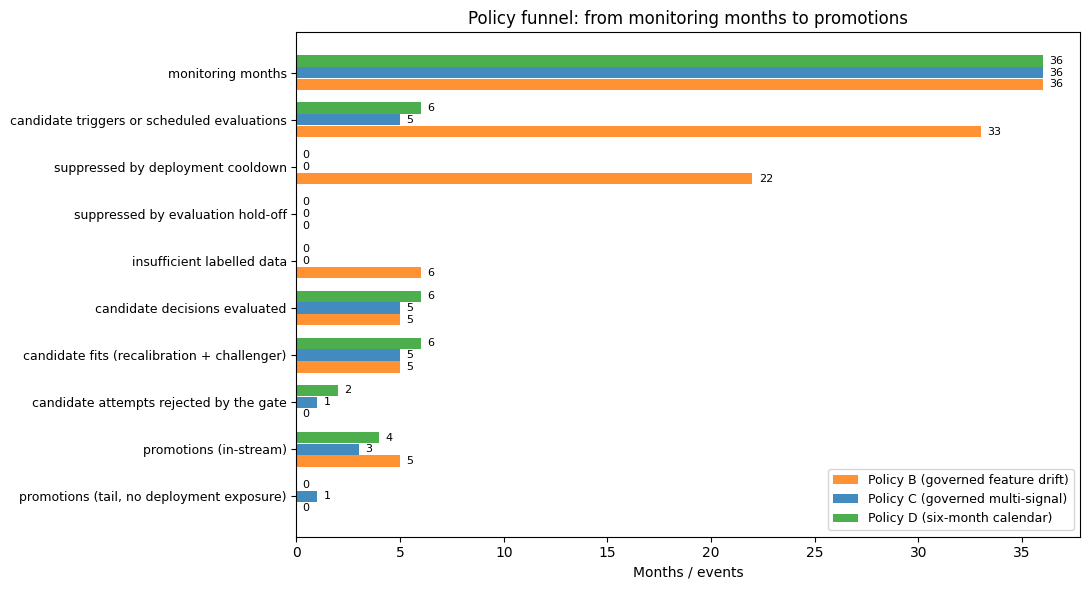

In [93]:
# Plot 1: policy funnel comparison
funnel_stages = policy_b_funnel["stage"].tolist()
y_positions = np.arange(len(funnel_stages))

fig, ax = plt.subplots(figsize=(11, 6))

for funnel, label, color, offset in [(policy_b_funnel, "Policy B (governed feature drift)", "tab:orange", 0.25),
                                     (policy_c_funnel, "Policy C (governed multi-signal)", "tab:blue", 0.0),
                                     (policy_d_funnel, "Policy D (six-month calendar)", "tab:green", -0.25)]:
    ax.barh(y_positions + offset, funnel["count"], height=0.24,
            color=color, alpha=0.85, label=label)

    for y, count in zip(y_positions + offset, funnel["count"]):
        ax.text(count + 0.3, y, str(count), va="center", fontsize=8)

ax.set_yticks(y_positions)
ax.set_yticklabels(funnel_stages, fontsize=9)
ax.invert_yaxis()

ax.set_xlabel("Months / events")
ax.set_title("Policy funnel: from monitoring months to promotions")
ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

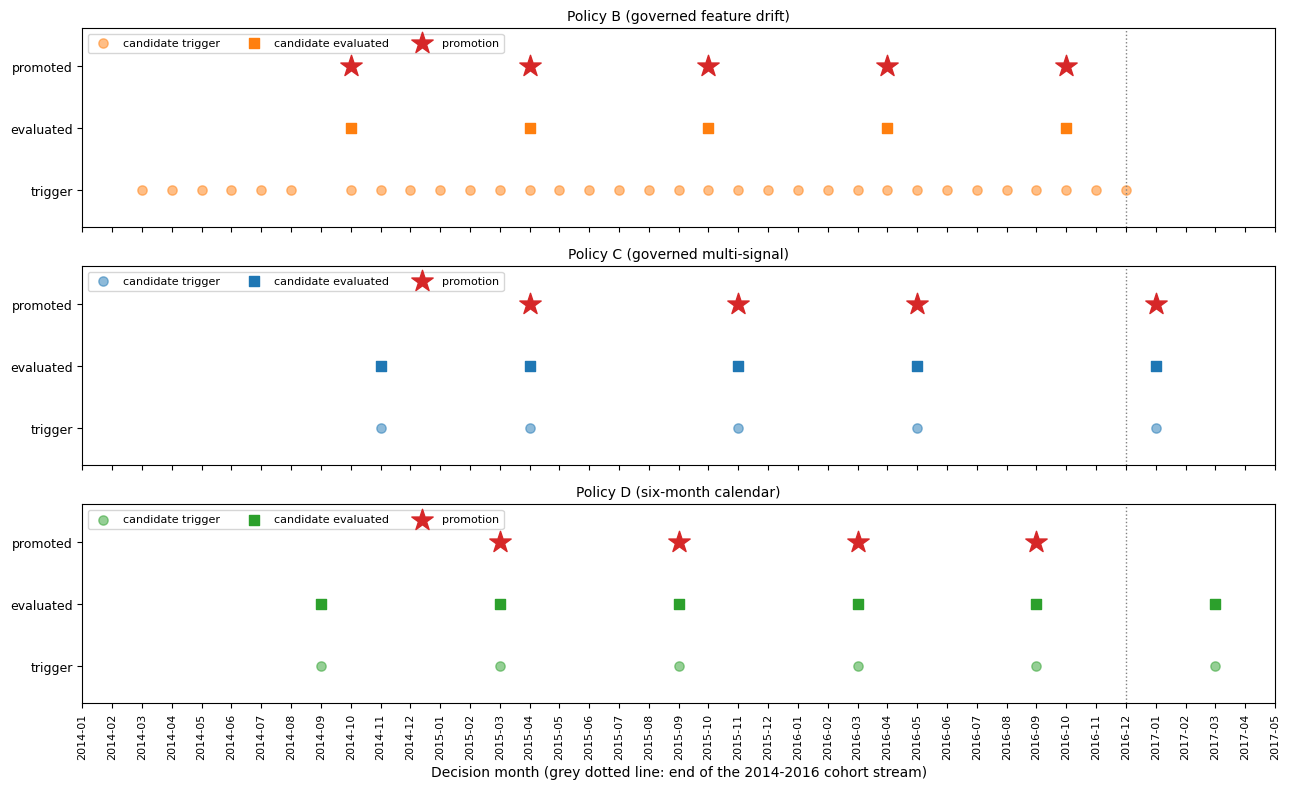

In [94]:
# Plot 2: candidate evaluations and promotions at decision_month
# The shared axis covers the full calendar from the first monitoring month to the last
# decision month, so every policy's events appear in chronological order
decision_axis = pd.period_range(all_monitor_months[0],
                                pd.Period(all_monitor_months[-1], freq="M") + label_delay_months,
                                freq="M").strftime("%Y-%m").tolist()

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

for ax, result, label, color in [(axes[0], policy_b, "Policy B (governed feature drift)", "tab:orange"),
                                 (axes[1], policy_c, "Policy C (governed multi-signal)", "tab:blue"),
                                 (axes[2], policy_d, "Policy D (six-month calendar)", "tab:green")]:
    decisions = result["decisions"]
    ax.plot(decision_axis, [np.nan] * len(decision_axis))  # fixes the shared month axis

    triggered = decisions[decisions["candidate_trigger"]]
    evaluated = decisions[decisions["candidate_evaluated"]]
    promoted = decisions[decisions["candidate_promoted"]]

    ax.scatter(triggered["decision_month"], [1] * triggered.shape[0],marker="o",s=45, 
               color=color, alpha=0.5, label="candidate trigger")

    ax.scatter(evaluated["decision_month"], [2] * evaluated.shape[0],marker="s", 
               s=55, color=color, label="candidate evaluated")

    ax.scatter(promoted["decision_month"], [3] * promoted.shape[0],marker="*", s=260, 
               color="tab:red", label="promotion")

    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels(["trigger", "evaluated", "promoted"], fontsize=9)
    ax.set_ylim(0.4, 3.6)
    ax.set_title(label, fontsize=10)
    ax.legend(loc="upper left", fontsize=8, ncols=3)
    ax.axvline(all_monitor_months[-1], color="grey", linestyle=":", linewidth=1)

axes[2].set_xticks(decision_axis)
axes[2].set_xticklabels(decision_axis, rotation=90, fontsize=8)
axes[2].set_xlabel("Decision month (grey dotted line: end of the 2014-2016 cohort stream)")

plt.tight_layout()
plt.show()

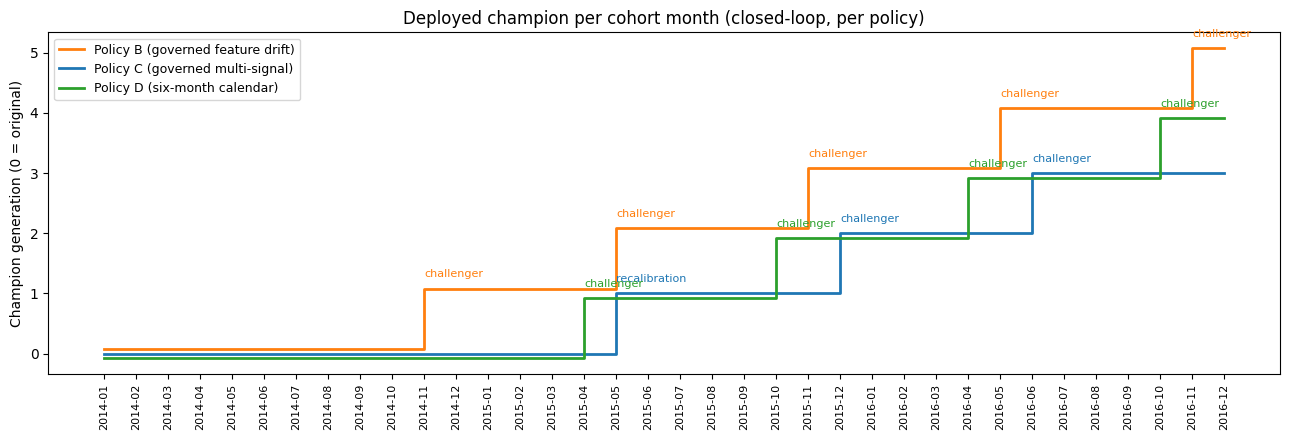

In [95]:
# Plot 3: deployed champion timeline for each governed policy
fig, ax = plt.subplots(figsize=(13, 4.5))

for result, label, color, offset in [(policy_b, "Policy B (governed feature drift)", "tab:orange", 0.08),
                                     (policy_c, "Policy C (governed multi-signal)", "tab:blue", 0.0),
                                     (policy_d, "Policy D (six-month calendar)", "tab:green", -0.08)]:
    managed = result["managed"]
    champion_order = list(dict.fromkeys(managed["deployed_champion"]))
    champion_index = managed["deployed_champion"].map({champion_id: i for i, champion_id in enumerate(champion_order)})

    ax.step(managed["monitor_month"], champion_index + offset, where="post",color=color, linewidth=2, label=label)

    for _, promotion in result["promotions"].iterrows():
        if promotion["in_stream"]:
            ax.annotate(promotion["action_type"],(promotion["first_cohort_scored"],champion_order.index(promotion["champion_id"]) + offset),
                        textcoords="offset points", xytext=(0, 8), fontsize=8, color=color)

ax.set_xticks(all_monitor_months)
ax.set_xticklabels(all_monitor_months, rotation=90, fontsize=8)
ax.set_ylabel("Champion generation (0 = original)")
ax.set_title("Deployed champion per cohort month (closed-loop, per policy)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

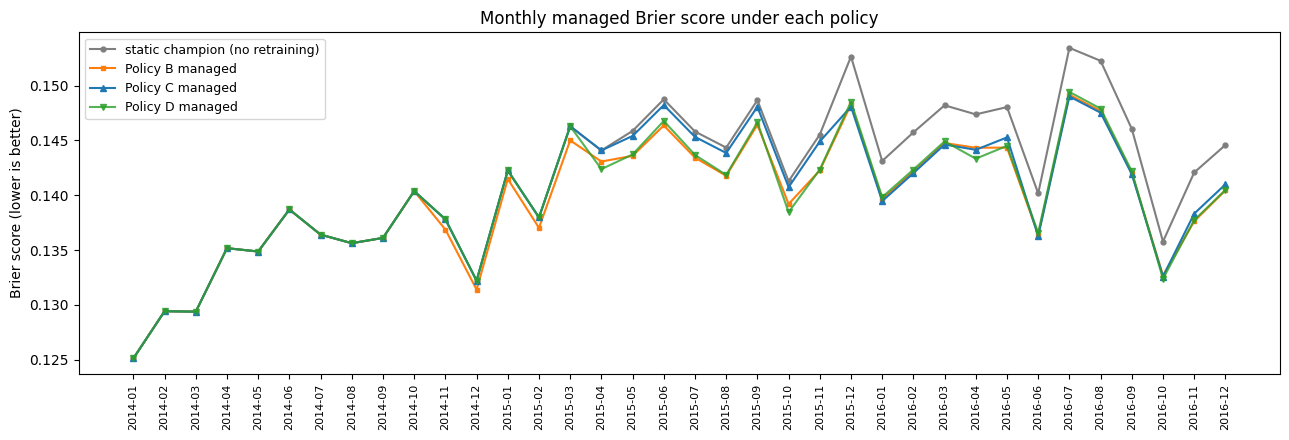

In [96]:
# Plot 4: monthly managed Brier score
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(static_managed["monitor_month"], static_managed["brier_score"],marker="o", markersize=3.5, 
        color="tab:grey", label="static champion (no retraining)")
ax.plot(policy_b_managed["monitor_month"], policy_b_managed["brier_score"],marker="s", 
        markersize=3.5, color="tab:orange", label="Policy B managed")
ax.plot(policy_c_managed["monitor_month"], policy_c_managed["brier_score"],marker="^", 
        markersize=4, color="tab:blue", label="Policy C managed")
ax.plot(policy_d_managed["monitor_month"], policy_d_managed["brier_score"],marker="v", 
        markersize=4, color="tab:green", alpha=0.8, label="Policy D managed")

ax.set_xticks(all_monitor_months)
ax.set_xticklabels(all_monitor_months, rotation=90, fontsize=8)
ax.set_ylabel("Brier score (lower is better)")
ax.set_title("Monthly managed Brier score under each policy")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

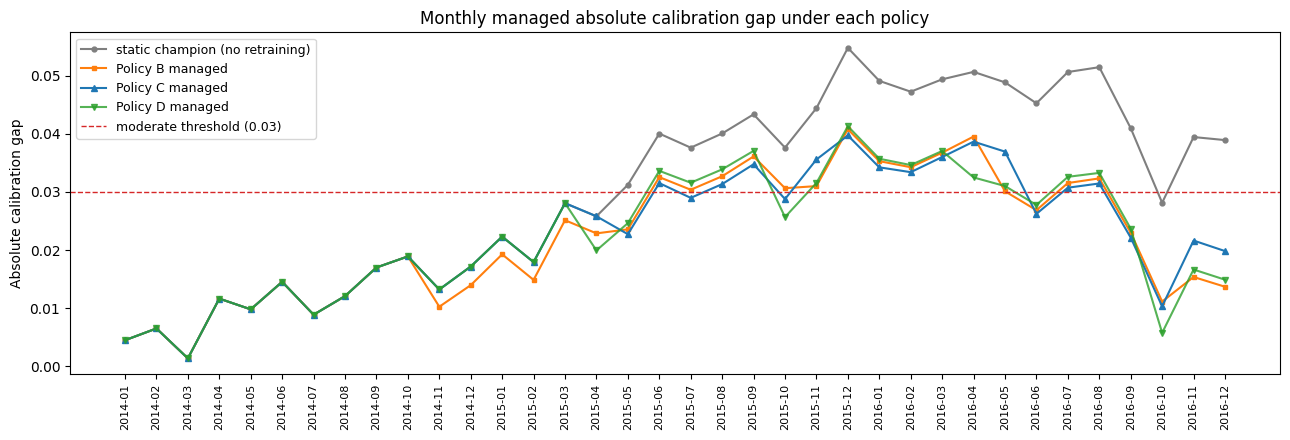

In [97]:
# Plot 5: monthly managed absolute calibration gap
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(static_managed["monitor_month"], static_managed["absolute_calibration_gap"],
        marker="o", markersize=3.5, color="tab:grey", label="static champion (no retraining)")
ax.plot(policy_b_managed["monitor_month"], policy_b_managed["absolute_calibration_gap"],
        marker="s", markersize=3.5, color="tab:orange", label="Policy B managed")
ax.plot(policy_c_managed["monitor_month"], policy_c_managed["absolute_calibration_gap"],
        marker="^", markersize=4, color="tab:blue", label="Policy C managed")
ax.plot(policy_d_managed["monitor_month"], policy_d_managed["absolute_calibration_gap"],
        marker="v", markersize=4, color="tab:green", alpha=0.8, label="Policy D managed")

ax.axhline(calibration_gap_moderate_threshold, color="tab:red", linestyle="--",
           linewidth=1, label=f"moderate threshold ({calibration_gap_moderate_threshold})")

ax.set_xticks(all_monitor_months)
ax.set_xticklabels(all_monitor_months, rotation=90, fontsize=8)
ax.set_ylabel("Absolute calibration gap")
ax.set_title("Monthly managed absolute calibration gap under each policy")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

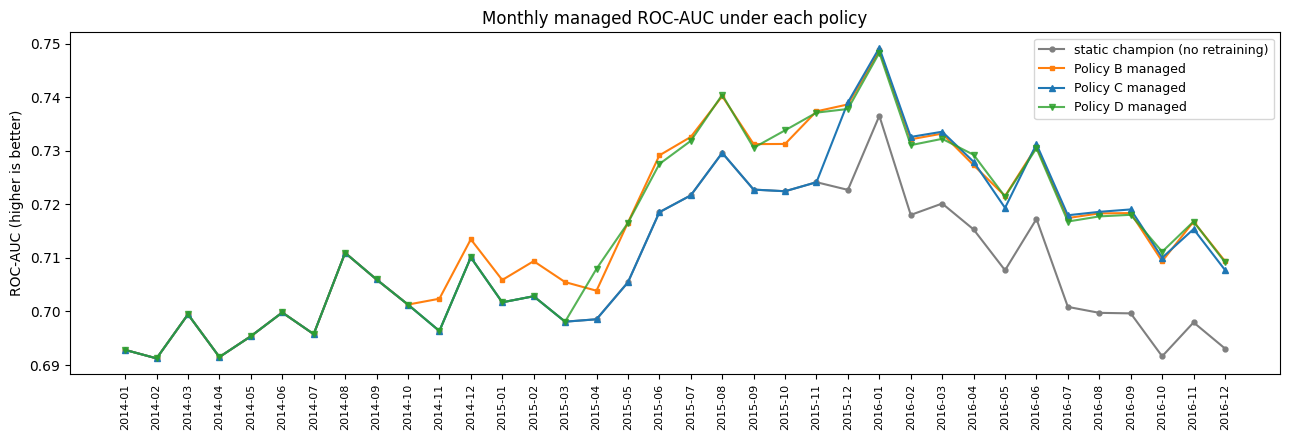

In [98]:
# Plot 6: monthly managed ROC-AUC
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(static_managed["monitor_month"], static_managed["roc_auc"],marker="o", 
        markersize=3.5, color="tab:grey", label="static champion (no retraining)")
ax.plot(policy_b_managed["monitor_month"], policy_b_managed["roc_auc"],marker="s", 
        markersize=3.5, color="tab:orange", label="Policy B managed")
ax.plot(policy_c_managed["monitor_month"], policy_c_managed["roc_auc"],
        marker="^", markersize=4, color="tab:blue", label="Policy C managed")
ax.plot(policy_d_managed["monitor_month"], policy_d_managed["roc_auc"],
        marker="v", markersize=4, color="tab:green", alpha=0.8, label="Policy D managed")

ax.set_xticks(all_monitor_months)
ax.set_xticklabels(all_monitor_months, rotation=90, fontsize=8)
ax.set_ylabel("ROC-AUC (higher is better)")
ax.set_title("Monthly managed ROC-AUC under each policy")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [99]:
# Plot 7: recalibration versus full retraining across fits and promotions
action_counts = pd.DataFrame([{"policy": "Policy B", "stage": "fits",
                               "recalibration": policy_b["recalibration_fits"],
                               "challenger": policy_b["challenger_fits"]},
                              {"policy": "Policy C", "stage": "fits",
                               "recalibration": policy_c["recalibration_fits"],
                               "challenger": policy_c["challenger_fits"]},
                              {"policy": "Policy B", "stage": "promotions",
                               "recalibration": int((policy_b["promotions"]["action_type"] == "recalibration").sum())
                                                if policy_b["promotions"].shape[0] > 0 else 0,
                               "challenger": int((policy_b["promotions"]["action_type"] == "challenger").sum())
                                             if policy_b["promotions"].shape[0] > 0 else 0},
                              {"policy": "Policy C", "stage": "promotions",
                               "recalibration": int((policy_c["promotions"]["action_type"] == "recalibration").sum())
                                                if policy_c["promotions"].shape[0] > 0 else 0,
                               "challenger": int((policy_c["promotions"]["action_type"] == "challenger").sum())
                                             if policy_c["promotions"].shape[0] > 0 else 0}])

x_positions = np.arange(action_counts.shape[0])
labels = action_counts["policy"] + "\n" + action_counts["stage"]

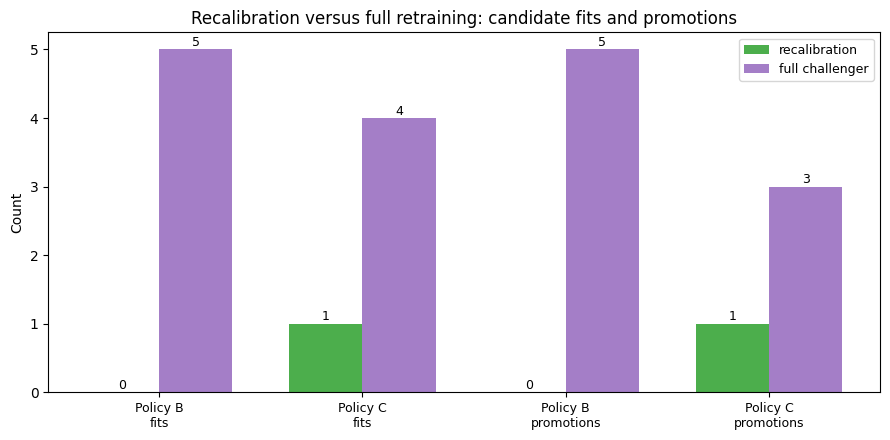

In [100]:
# Compare recalibration and challenger activity
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.bar(x_positions - 0.18, action_counts["recalibration"], width=0.36,
       color="tab:green", alpha=0.85, label="recalibration")

ax.bar(x_positions + 0.18, action_counts["challenger"], width=0.36,
       color="tab:purple", alpha=0.85, label="full challenger")

for x, (recalibration, challenger) in enumerate(zip(action_counts["recalibration"],
                                                    action_counts["challenger"])):
    ax.text(x - 0.18, recalibration + 0.05, str(recalibration), ha="center", fontsize=9)
    ax.text(x + 0.18, challenger + 0.05, str(challenger), ha="center", fontsize=9)

ax.set_xticks(x_positions)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Count")
ax.set_title("Recalibration versus full retraining: candidate fits and promotions")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 13. Sensitivity Analyses

The sensitivity analysis tests how the results change under different label delays, deployment cooldowns and gate settings. For these three families, Policies B and C are rerun through the full closed-loop process, including candidate fitting, validation, the deployment gate and subsequent champion updates. The primary settings reuse the original runs.

A fourth sensitivity checks the effect of `initial_list_status` on feature-drift behaviour. Policy B is rerun using the feature-drift trigger that excludes this variable, while Policy A is compared using its request counts under both feature definitions.

Policy D is not rerun across these settings. Its fixed six-month schedule is used as the calendar comparator in the primary analysis, and its cooldown and hold-off are already disabled by design.

In [101]:
# One helper produces the same summary row for every scenario
def sensitivity_rows(setting_name, setting_value, result_b, result_c):
    rows = []

    for policy_label, result in [("policy_B", result_b), ("policy_C", result_c)]:
        summary = summarise_policy_results(result, policy_label)

        rows.append({"sensitivity": setting_name,
                     "setting": setting_value,
                     "policy": policy_label,
                     "candidate_triggers": summary["candidate_triggers"],
                     "candidate_fits": summary["total_candidate_fits"],
                     "candidate_rejections": summary["candidate_attempt_rejections"],
                     "promotions_in_stream": summary["promotions_in_stream"],
                     "promotions_tail": summary["promotions_tail"],
                     "managed_brier": summary["mean_monthly_brier"],
                     "managed_calibration_gap": summary["mean_abs_calibration_gap"],
                     "managed_roc_auc": summary["mean_roc_auc"]})

    return rows

In [102]:
# Family 1: label delay. Family 2: deployment cooldown. Family 3: deployment gate
scenario_families = ([("label_delay_months", delay, {"label_delay": delay})
                      for delay in [3, 5, 9]] +
                     [("deployment_cooldown_months", cooldown,
                       {"deployment_cooldown": cooldown})
                      for cooldown in [3, 6, 9]] +
                     [("deployment_gate", gate["name"], {"gate": gate})
                      for gate in [GATE_PERMISSIVE, GATE_PRIMARY, GATE_STRICT]])

primary_settings = {("label_delay_months", 5),
                    ("deployment_cooldown_months", 6),
                    ("deployment_gate", "primary")}

In [103]:
# Run each sensitivity scenario and collect the policy summaries
all_sensitivity_rows = []

for setting_name, setting_value, overrides in scenario_families:
    if (setting_name, setting_value) in primary_settings:
        result_b, result_c = policy_b, policy_c  # reuse the primary runs
    else:
        print(f"Running sensitivity: {setting_name} = {setting_value} ...")

        gate = overrides.pop("gate", GATE_PRIMARY)

        result_b = run_governed_policy("policy_b_governed_feature_drift",
                                       "feature_drift", gate,
                                       verbose=False, **overrides)

        result_c = run_governed_policy("policy_c_governed_multi_signal",
                                       "multi_signal", gate,
                                       verbose=False, **overrides)

    all_sensitivity_rows.extend(
        sensitivity_rows(setting_name, setting_value, result_b, result_c))

print("Label-delay, cooldown and gate sensitivities complete.")

Running sensitivity: label_delay_months = 3 ...
Running sensitivity: label_delay_months = 9 ...
Running sensitivity: deployment_cooldown_months = 3 ...
Running sensitivity: deployment_cooldown_months = 9 ...
Running sensitivity: deployment_gate = permissive ...
Running sensitivity: deployment_gate = strict ...
Label-delay, cooldown and gate sensitivities complete.


In [104]:
# Family 4: platform-policy feature treatment
# Policy A is a pure request count under both definitions; the governed Policy B path is rerun
# with the feature-drift trigger that excludes initial_list_status. The trigger column is a
# parameter of the engine, so the exclusion is handled internally rather than by editing tables
print("Running sensitivity: feature drift excluding the platform-policy feature ...")

policy_b_excl_policy = run_governed_policy(
    "policy_b_governed_feature_drift_excl_policy", "feature_drift", GATE_PRIMARY,
    feature_trigger_col="feature_drift_trigger_excl_policy", verbose=False)

Running sensitivity: feature drift excluding the platform-policy feature ...


In [105]:
# Add both platform-policy feature settings to the sensitivity results
for policy_label, result in [("policy_B", policy_b),
                             ("policy_B", policy_b_excl_policy)]:
    summary = summarise_policy_results(result, policy_label)

    all_sensitivity_rows.append(
        {"sensitivity": "platform_policy_feature",
         "setting": "all_features" if result is policy_b else "excl_initial_list_status",
         "policy": policy_label,
         "candidate_triggers": summary["candidate_triggers"],
         "candidate_fits": summary["total_candidate_fits"],
         "candidate_rejections": summary["candidate_attempt_rejections"],
         "promotions_in_stream": summary["promotions_in_stream"],
         "promotions_tail": summary["promotions_tail"],
         "managed_brier": summary["mean_monthly_brier"],
         "managed_calibration_gap": summary["mean_abs_calibration_gap"],
         "managed_roc_auc": summary["mean_roc_auc"]})

print("\nPolicy A request counts under both feature-drift definitions:")

display(policy_a_summary[["baseline_policy_name", "retraining_requests",
                          "requests_without_delayed_deterioration"]])


Policy A request counts under both feature-drift definitions:


,baseline_policy_name,retraining_requests,requests_without_delayed_deterioration
0,feature_drift_only_all_features,33,6
1,feature_drift_only_excluding_platform_policy,27,6


In [106]:
# Combined sensitivity summary: one table across all four families
policy_sensitivity_summary = pd.DataFrame(all_sensitivity_rows)
display(policy_sensitivity_summary.round(4))

,sensitivity,setting,policy,candidate_triggers,candidate_fits,candidate_rejections,promotions_in_stream,promotions_tail,managed_brier,managed_calibration_gap,managed_roc_auc
0,label_delay_months,3,policy_B,33,6,1,5,0,0.1395,0.0206,0.7165
1,label_delay_months,3,policy_C,6,5,1,4,0,0.1400,0.0214,0.7137
2,label_delay_months,5,policy_B,33,5,0,5,0,0.1397,0.0222,0.7157
3,label_delay_months,5,policy_C,5,5,1,3,1,0.1402,0.0229,0.7127
4,label_delay_months,9,policy_B,33,6,2,4,0,0.1403,0.0250,0.7135
5,label_delay_months,9,policy_C,4,4,1,2,1,0.1409,0.0254,0.7098
6,deployment_cooldown_months,3,policy_B,33,11,4,6,1,0.1397,0.0220,0.7158
7,deployment_cooldown_months,3,policy_C,5,5,1,3,1,0.1402,0.0229,0.7127
8,deployment_cooldown_months,6,policy_B,33,5,0,5,0,0.1397,0.0222,0.7157
9,deployment_cooldown_months,6,policy_C,5,5,1,3,1,0.1402,0.0229,0.7127


The overall Policy B versus Policy C pattern is stable across the sensitivity runs. Policy B has slightly lower Brier score and higher ROC-AUC in every paired scenario. Its calibration gap is also lower in eight of the nine comparisons, with the strict-gate setting the only exception. Longer label delays reduce performance for both policies, with higher Brier and calibration gaps and lower ROC-AUC at nine months.

The cooldown has a much larger effect on Policy B's intervention workload than on its managed performance. With a three-month cooldown, Policy B fits 11 candidates, compared with five under the primary six-month setting and three at nine months, while its performance metrics change only slightly. Policy C is unchanged between the three- and six-month settings and changes only under the longer nine-month cooldown.

Gate strictness mainly affects Policy B: under the strict gate it fits eight candidates, rejects five and promotes three. Policy C is unchanged under the strict gate, while the permissive gate changes its trajectory but still results in four total promotions. Excluding `initial_list_status` reduces Policy A requests from 33 to 27 and Policy B triggers from 33 to 27, with Policy B fits falling from five to four.

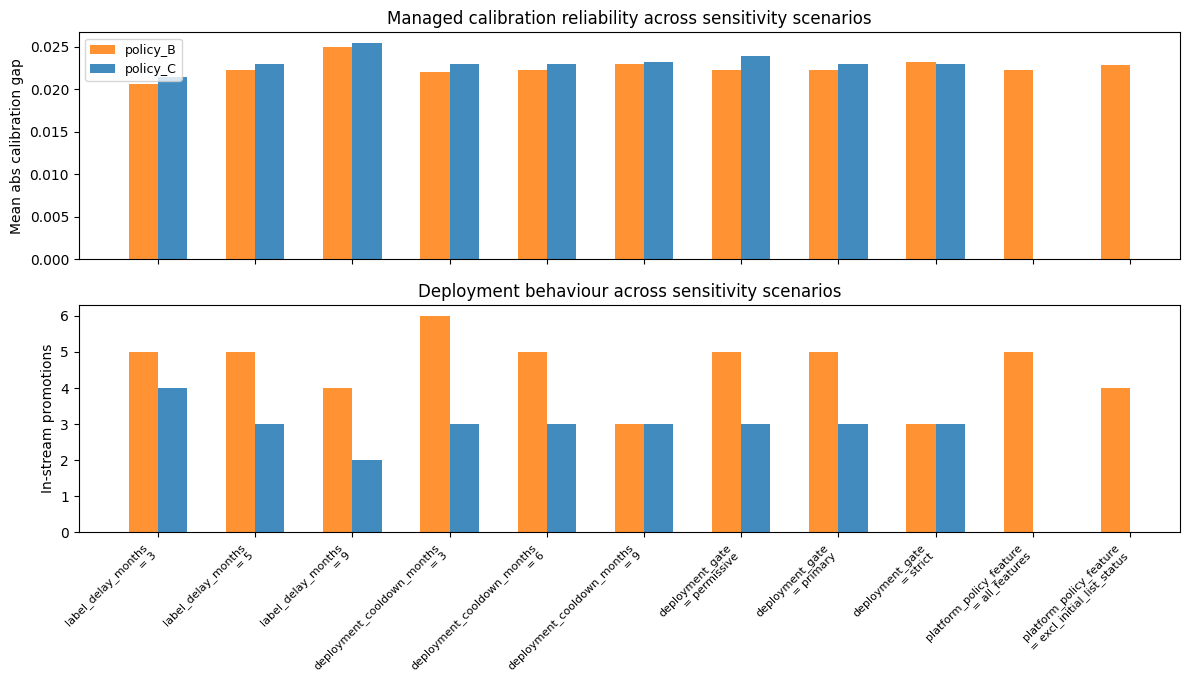

In [107]:
#sensitivity of managed reliability and deployment behaviour
sensitivity_plot_df = policy_sensitivity_summary.copy()
sensitivity_plot_df["scenario"] = (sensitivity_plot_df["sensitivity"] + "\n= " +
                                   sensitivity_plot_df["setting"].astype(str))

scenario_order = list(dict.fromkeys(sensitivity_plot_df["scenario"]))
x_positions = np.arange(len(scenario_order))

# Compare managed reliability and promotions across sensitivity scenarios
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for policy_label, color, offset in [("policy_B", "tab:orange", -0.15),
                                    ("policy_C", "tab:blue", 0.15)]:
    subset = (sensitivity_plot_df[sensitivity_plot_df["policy"] == policy_label]
        .set_index("scenario")
        .reindex(scenario_order))

    axes[0].bar(x_positions + offset, subset["managed_calibration_gap"], width=0.3,
                color=color, alpha=0.85, label=policy_label)

    axes[1].bar(x_positions + offset, subset["promotions_in_stream"], width=0.3,
                color=color, alpha=0.85, label=policy_label)

axes[0].set_ylabel("Mean abs calibration gap")
axes[0].set_title("Managed calibration reliability across sensitivity scenarios")
axes[0].legend(fontsize=9)

axes[1].set_ylabel("In-stream promotions")
axes[1].set_title("Deployment behaviour across sensitivity scenarios")
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(scenario_order, rotation=45, ha="right", fontsize=8)

plt.tight_layout()
plt.show()

In [108]:
# Assemble the block-length qualification from the executed robustness tables
block_failures = bootstrap_block_length_summary.loc[
    ~bootstrap_block_length_summary["practically_noninferior"]]

longest_block = max(BOOTSTRAP_BLOCK_LENGTHS)

held_at_longest = sorted(bootstrap_block_length_summary.loc[
    (bootstrap_block_length_summary["block_months"] == longest_block) &
    bootstrap_block_length_summary["practically_noninferior"], "metric"])

if block_failures.empty:
    block_qualification = ("The verdict was unchanged across every tested block length "
                           f"({BOOTSTRAP_BLOCK_LENGTHS} months).")
else:
    failure_text = "; ".join(f"{row['metric']} at {int(row['block_months'])}-month blocks, where the "
                             f"upper bound was {row['ci_high_95']:.5f} against a margin of "
                             f"{row['noninferiority_margin']}"
                             for _, row in block_failures.iterrows())

    block_qualification = (f"Under {longest_block}-month blocks non-inferiority still held for "
                           f"{' and '.join(held_at_longest)}, but narrowly failed for {failure_text}, "
                           "so that conclusion is specification-dependent.")

calendar_offset = calendar_similarity["common_evaluation_offset_months"]

print(block_qualification)

Under 6-month blocks non-inferiority still held for absolute_calibration_gap and roc_auc, but narrowly failed for brier_score at 6-month blocks, where the upper bound was 0.00116 against a margin of 0.001, so that conclusion is specification-dependent.


In [109]:
# The supported claim is assembled from the run so it cannot drift from the numbers
calendar_verdict = (f"its {calendar_similarity['paired_in_stream_evaluations']} in-stream evaluation "
                    f"months fell exactly {calendar_offset} month after the independently derived "
                    f"{calendar_interval_months}-month calendar, with differing gate outcomes producing "
                    f"{int(summary_b['promotions_in_stream'])} promotions against the calendar baseline's "
                    f"{int(summary_d['promotions_in_stream'])}"
                    if calendar_offset is not None else
                    "its evaluation months did not sit at a constant offset from the calendar baseline")

calendar_baseline_text = ("held on every metric at every tested block length"
                          if policy_c_vs_d_block_length_consistent else
                          "did not hold at every tested block length")

supported_claim = (
    f"Over {expected_month_count} monthly cohorts under a {label_delay_months}-month simulated label "
    f"delay, the governed multi-signal policy reduced intervention requests from "
    f"{int(policy_a_summary.loc[0, 'retraining_requests'])} under the naive feature-drift baseline to "
    f"{int(summary_c['candidate_triggers'])} policy triggers, and reduced in-stream deployments from "
    f"{int(summary_b['promotions_in_stream'])} under the governed feature-drift baseline to "
    f"{int(summary_c['promotions_in_stream'])}. It did not reduce candidate fitting: Policy B and "
    f"Policy C each fitted {int(summary_c['total_candidate_fits'])} candidates. Policy C met all "
    f"{len(NONINFERIORITY_MARGINS)} declared practical margins relative to Policy B under the primary "
    f"{BOOTSTRAP_BLOCK_MONTHS}-month moving-block specification and under "
    f"{min(BOOTSTRAP_BLOCK_LENGTHS)}-month blocks. {block_qualification} Against the "
    f"{calendar_interval_months}-month calendar baseline, non-inferiority {calendar_baseline_text}. "
    f"Policy B was approximately schedule-like: {calendar_verdict}. The contribution is selective, "
    "delayed-outcome-aware and auditable governance, not predictive superiority and not a demonstrated "
    "reduction in retraining cost.")

print(supported_claim)

Over 36 monthly cohorts under a 5-month simulated label delay, the governed multi-signal policy reduced intervention requests from 33 under the naive feature-drift baseline to 5 policy triggers, and reduced in-stream deployments from 5 under the governed feature-drift baseline to 3. It did not reduce candidate fitting: Policy B and Policy C each fitted 5 candidates. Policy C met all 3 declared practical margins relative to Policy B under the primary 3-month moving-block specification and under 2-month blocks. Under 6-month blocks non-inferiority still held for absolute_calibration_gap and roc_auc, but narrowly failed for brier_score at 6-month blocks, where the upper bound was 0.00116 against a margin of 0.001, so that conclusion is specification-dependent. Against the 6-month calendar baseline, non-inferiority held on every metric at every tested block length. Policy B was approximately schedule-like: its 5 in-stream evaluation months fell exactly 1 month after the independently deriv

## 14. Saving Notebook 05 Outputs

The decision, attempt, promotion and managed-performance tables are saved along with every promoted champion exactly as deployed. These are the artefacts behind the results chapter, and the promoted models are kept so a deployment can be reproduced without rerunning the whole policy.

In [110]:
# Tables behind the results chapter
policy_a_requests.to_csv(f"{policy_dir}/policy_A_requests.csv", index=False)

policy_b["decisions"].to_csv(f"{policy_dir}/policy_B_decisions.csv", index=False)
policy_c["decisions"].to_csv(f"{policy_dir}/policy_C_decisions.csv", index=False)
policy_d["decisions"].to_csv(f"{policy_dir}/policy_D_decisions.csv", index=False)

policy_b["attempts"].to_csv(f"{policy_dir}/policy_B_candidate_attempts.csv", index=False)
policy_c["attempts"].to_csv(f"{policy_dir}/policy_C_candidate_attempts.csv", index=False)
policy_d["attempts"].to_csv(f"{policy_dir}/policy_D_candidate_attempts.csv", index=False)

policy_b["promotions"].to_csv(f"{policy_dir}/policy_B_promotions.csv", index=False)
policy_c["promotions"].to_csv(f"{policy_dir}/policy_C_promotions.csv", index=False)
policy_d["promotions"].to_csv(f"{policy_dir}/policy_D_promotions.csv", index=False)

static_managed.to_csv(f"{policy_dir}/managed_performance_static.csv", index=False)
policy_b_managed.to_csv(f"{policy_dir}/managed_performance_B.csv", index=False)
policy_c_managed.to_csv(f"{policy_dir}/managed_performance_C.csv", index=False)
policy_d_managed.to_csv(f"{policy_dir}/managed_performance_D.csv", index=False)

policy_comparison_summary.to_csv(f"{policy_dir}/policy_comparison_summary.csv", index=False)
policy_tradeoff_summary.to_csv(f"{policy_dir}/policy_tradeoff_summary.csv", index=False)
policy_timing_summary.to_csv(f"{policy_dir}/policy_timing_summary.csv", index=False)
calendar_comparison.to_csv(f"{policy_dir}/policy_B_vs_D_calendar_comparison.csv", index=False)
calendar_offset_diagnostic.to_csv(f"{policy_dir}/policy_B_vs_D_calendar_offset.csv", index=False)
reference_optimism_summary.to_csv(f"{policy_dir}/promoted_reference_optimism.csv", index=False)
policy_sensitivity_summary.to_csv(f"{policy_dir}/policy_sensitivity_summary.csv", index=False)

In [111]:
# Statistical summaries behind the interpretation
policy_bc_bootstrap.to_csv(f"{policy_dir}/policy_B_vs_C_bootstrap.csv", index=False)
policy_b_vs_d_bootstrap.to_csv(f"{policy_dir}/policy_B_vs_D_bootstrap.csv", index=False)
static_versus_governed_bootstrap.to_csv(f"{policy_dir}/static_versus_governed_bootstrap.csv",
                                        index=False)

policy_c_noninferiority_summary.to_csv(f"{policy_dir}/policy_C_noninferiority_summary.csv",
                                      index=False)
policy_c_vs_d_noninferiority_summary.to_csv(f"{policy_dir}/policy_C_vs_D_noninferiority_summary.csv",
                                            index=False)

bootstrap_block_length_summary.to_csv(f"{policy_dir}/bootstrap_block_length_summary.csv", index=False)
policy_c_vs_d_block_length_summary.to_csv(f"{policy_dir}/policy_C_vs_D_block_length_summary.csv",
                                          index=False)

statistical_summary_files = ["policy_B_vs_C_bootstrap.csv",
                             "policy_B_vs_D_bootstrap.csv",
                             "static_versus_governed_bootstrap.csv",
                             "policy_C_noninferiority_summary.csv",
                             "policy_C_vs_D_noninferiority_summary.csv",
                             "bootstrap_block_length_summary.csv",
                             "policy_C_vs_D_block_length_summary.csv",
                             "policy_B_vs_D_calendar_offset.csv",
                             "promoted_reference_optimism.csv"]

In [112]:
# Save every promoted champion exactly as deployed (underlying model + calibration layer)
promoted_model_files = []

for result in [policy_b, policy_c, policy_d]:
    for _, promotion in result["promotions"].iterrows():
        champion_state = result["champion_registry"][promotion["champion_id"]]
        file_name = f"promoted_{result['policy_name']}_{promotion['champion_id']}.joblib"

        joblib.dump({"policy": result["policy_name"],
                     "champion_id": champion_state["champion_id"],
                     "action_type": champion_state["action_type"],
                     "deployment_month": champion_state["deployment_month"],
                     "underlying_model": champion_state["underlying_model"],
                     "active_recalibration_map": champion_state["active_recalibration_map"],
                     "reference": champion_state["reference"]},
                    f"{policy_dir}/{file_name}")

        promoted_model_files.append(file_name)

In [113]:
# Save the final policy metadata
final_policy_metadata = {"notebook": "05_multi_signal_retraining_policy_and_champion_challenger",
                         "policy_engine": ("closed-loop calendar-month simulation: each cohort is scored by the champion "
                                           "active at the start of that month, deployed probabilities are frozen, and delayed "
                                           "evidence is computed from those probabilities against the reference of the champion "
                                           "that issued them"),
                         "label_delay_months": label_delay_months,
                         "validation_window_months": validation_window_months,
                         "deployment_cooldown_months": deployment_cooldown_months,
                         "candidate_evaluation_holdoff_months": candidate_evaluation_holdoff_months,
                         "persistence_cohorts": persistence_cohorts,
                         "deployment_gates": {"primary": GATE_PRIMARY,
                                              "permissive": GATE_PERMISSIVE,
                                              "strict": GATE_STRICT},
                         "practical_noninferiority_margins": NONINFERIORITY_MARGINS,
                         "bootstrap_reporting": {"resamples": BOOTSTRAP_RESAMPLES,
                                                 "primary_moving_block_months": BOOTSTRAP_BLOCK_MONTHS,
                                                 "block_lengths_tested": BOOTSTRAP_BLOCK_LENGTHS,
                                                 "policy_c_vs_b_stable_across_block_lengths": bool(block_length_consistent),
                                                 "policy_c_vs_d_stable_across_block_lengths":
                                                     bool(policy_c_vs_d_block_length_consistent),
                                                 "policy_c_vs_b_block_length_failures":
                                                     [{"metric": row["metric"],
                                                       "block_months": int(row["block_months"]),
                                                       "ci_high_95": float(row["ci_high_95"]),
                                                       "noninferiority_margin": float(row["noninferiority_margin"])}
                                                      for _, row in block_failures.iterrows()],
                                                 "block_length_qualification": block_qualification},
                         "action_fork_thresholds": {"auc_drop_fork_threshold": AUC_DROP_FORK_THRESHOLD,
                                                    "calibration_slope_deviation": CALIBRATION_SLOPE_DEVIATION,
                                                    "residual_bin_shift_threshold": RESIDUAL_BIN_SHIFT_THRESHOLD},
                         "policy_c_trigger_rules": {"R1": "delayed performance deterioration high",
                                                    "R2": ("performance at least moderate AND (score-conditional level high OR "
                                                           "residual bin shift at or above threshold)"),
                                                    "R3": ("performance at least moderate persisting for at least two consecutive "
                                                           "mature cohorts of the same champion AND corroborated by target drift, "
                                                           "residual deterioration or an earlier warning for those cohorts"),
                                                    "never_alone": "feature drift, prediction drift, target drift, data quality"},
                         "policy_d": {"purpose": ("diagnostic control for the calendar confound: feature drift fires in almost "
                                                  "every month, so Policy B may be timed by its cooldown rather than by its trigger"),
                                      "schedule_rule": f"fixed {calendar_interval_months}-month calendar from the first eligible month",
                                      "calendar_interval_months": calendar_interval_months,
                                      "first_eligible_month_rule": ("earliest decision month with a non-empty chronological training "
                                                                    "window and a complete validation window under the same label delay; "
                                                                    "no monitoring signal and no observed promotion date is consulted"),
                                      "first_eligible_month": calendar_schedule_primary[0],
                                      "calendar_schedule": calendar_schedule_primary,
                                      "candidate_type": "full challenger, identical to Policy B",
                                      "gate": GATE_PRIMARY["name"],
                                      "deployment_cooldown_months": 0,
                                      "candidate_evaluation_holdoff_months": 0,
                                      "timing_rule_note": ("the calendar sets the cadence, so the cooldown and hold-off are disabled "
                                                           "to avoid a second timing rule altering the declared schedule")},
                         "parity_check_passed": bool(parity_passed),
                         "sensitivity_families": sorted(policy_sensitivity_summary["sensitivity"].unique().tolist()),
                         "sensitivity_settings": {family: sorted(set(str(value) for value in group["setting"]))
                                                  for family, group in policy_sensitivity_summary.groupby("sensitivity")},
                         "statistical_summary_files": statistical_summary_files,
                         "results": {"policy_a_requests": int(policy_a_summary.loc[0, "retraining_requests"]),
                                     "policy_a_requests_without_delayed_deterioration":
                                         int(policy_a_summary.loc[0, "requests_without_delayed_deterioration"]),
                                     "policy_b_candidate_triggers":
                                         int(policy_b["decisions"]["candidate_trigger"].sum()),
                                     "policy_b_candidate_fits":
                                         int(policy_comparison_summary.loc[1, "total_candidate_fits"]),
                                     "policy_b_promotions_in_stream":
                                         int(policy_comparison_summary.loc[1, "promotions_in_stream"]),
                                     "policy_b_promotions_tail":
                                         int(policy_comparison_summary.loc[1, "promotions_tail"]),
                                     "policy_b_champion_active_at_stream_end":
                                         str(policy_comparison_summary.loc[1, "champion_active_at_stream_end"]),
                                     "policy_c_candidate_triggers":
                                         int(policy_c["decisions"]["candidate_trigger"].sum()),
                                     "policy_c_candidate_fits":
                                         int(policy_comparison_summary.loc[2, "total_candidate_fits"]),
                                     "policy_c_promotions_in_stream":
                                         int(policy_comparison_summary.loc[2, "promotions_in_stream"]),
                                     "policy_c_promotions_tail":
                                         int(policy_comparison_summary.loc[2, "promotions_tail"]),
                                     "policy_c_champion_active_at_stream_end":
                                         str(policy_comparison_summary.loc[2, "champion_active_at_stream_end"]),
                                     "policy_d_scheduled_evaluations":
                                         int(policy_d["decisions"]["candidate_trigger"].sum()),
                                     "policy_d_candidate_fits":
                                         int(policy_comparison_summary.loc[3, "total_candidate_fits"]),
                                     "policy_d_promotions_in_stream":
                                         int(policy_comparison_summary.loc[3, "promotions_in_stream"]),
                                     "policy_d_promotions_tail":
                                         int(policy_comparison_summary.loc[3, "promotions_tail"]),
                                     "policy_d_champion_active_at_stream_end":
                                         str(policy_comparison_summary.loc[3, "champion_active_at_stream_end"]),
                                     "calendar_similarity": calendar_similarity,
                                     "evaluation_schedule_offset_months": calendar_offset,
                                     "policy_b_vs_d_any_interval_excludes_zero": bool(policy_b_vs_d_material),
                                     "static_versus_governed_intervals_excluding_zero":
                                         int(static_versus_governed_bootstrap["excludes_zero"].sum()),
                                     "policy_c_noninferior_to_b_primary_blocks":
                                         bool(policy_c_noninferiority_summary["policy_c_practically_noninferior"].all()),
                                     "policy_c_noninferior_to_d_primary_blocks":
                                         bool(policy_c_vs_d_noninferiority_summary["practically_noninferior"].all()),
                                     "reference_optimism_median_brier_change":
                                         reference_optimism_median_brier_change,
                                     "reference_optimism_median_auc_drop":
                                         reference_optimism_median_auc_drop,
                                     "reference_optimism_negative_auc_drops":
                                         reference_optimism_negative_auc_drops,
                                     "reference_optimism_promotions": reference_optimism_promotions},
                         "supported_claim": supported_claim,
                         "notes": ["The final gate settings were fixed after diagnostic review of earlier prototypes and "
                                   "were not changed according to the new promotion count.",
                                   "Challengers and recalibrations use action-specific acceptance criteria because they "
                                   "serve different purposes.",
                                   "All gate, fork, governance and non-inferiority thresholds are transparent study "
                                   "choices, not academic or industry standards.",
                                   "The five-month label delay is a simulation device for label latency. Lending Club "
                                   "outcomes mature over 36 or 60-month contractual terms, so the policies received "
                                   "outcome information substantially earlier than a lender would.",
                                   "Managed performance is retrospective evaluation from frozen deployed probabilities; "
                                   "labels used in it were not available at decision time.",
                                   "Policy C raised fewer alerts than Policy B but fitted the same number of candidates, "
                                   "so no computational saving is claimed.",
                                   "A promoted champion's monitoring reference is the validation window that accepted it, "
                                   "so its baseline metrics are selected rather than independent. The measured optimism is "
                                   "mild and is not systematic for ranking.",
                                   "Schedule divergence between Policy B and Policy D is measured on paired in-stream "
                                   "evaluation months, never on promotion lists of unequal length.",
                                   "Non-inferiority of Policy C relative to Policy B is specification-dependent for Brier "
                                   "score: it holds at 2 and 3-month blocks and narrowly fails at 6-month blocks."]}

In [114]:
# Write the final policy metadata to JSON
with open(f"{policy_dir}/final_policy_metadata.json", "w") as f:
    json.dump(final_policy_metadata, f, indent=2)

print("Saved:", f"{policy_dir}/final_policy_metadata.json")

Saved: ../artifacts/retraining_policy/final_policy_metadata.json


In [115]:
# Every saved artefact must load back with the expected shape
reload_comparison = pd.read_csv(f"{policy_dir}/policy_comparison_summary.csv")
reload_tradeoff = pd.read_csv(f"{policy_dir}/policy_tradeoff_summary.csv")
reload_noninferiority = pd.read_csv(f"{policy_dir}/policy_C_noninferiority_summary.csv")
reload_noninferiority_cd = pd.read_csv(f"{policy_dir}/policy_C_vs_D_noninferiority_summary.csv")
reload_block_lengths = pd.read_csv(f"{policy_dir}/bootstrap_block_length_summary.csv")
reload_block_lengths_cd = pd.read_csv(f"{policy_dir}/policy_C_vs_D_block_length_summary.csv")
reload_bc_bootstrap = pd.read_csv(f"{policy_dir}/policy_B_vs_C_bootstrap.csv")
reload_bd_bootstrap = pd.read_csv(f"{policy_dir}/policy_B_vs_D_bootstrap.csv")
reload_static_bootstrap = pd.read_csv(f"{policy_dir}/static_versus_governed_bootstrap.csv")
reload_calendar_offset = pd.read_csv(f"{policy_dir}/policy_B_vs_D_calendar_offset.csv")
reload_reference_optimism = pd.read_csv(f"{policy_dir}/promoted_reference_optimism.csv")
reload_managed_b = pd.read_csv(f"{policy_dir}/managed_performance_B.csv")
reload_managed_c = pd.read_csv(f"{policy_dir}/managed_performance_C.csv")
reload_managed_d = pd.read_csv(f"{policy_dir}/managed_performance_D.csv")
reload_timing = pd.read_csv(f"{policy_dir}/policy_timing_summary.csv")
reload_calendar = pd.read_csv(f"{policy_dir}/policy_B_vs_D_calendar_comparison.csv")
reload_sensitivity = pd.read_csv(f"{policy_dir}/policy_sensitivity_summary.csv")

with open(f"{policy_dir}/final_policy_metadata.json") as f:
    reload_metadata = json.load(f)

## 15. Summary and Limitations

The main trade-off is between intervention selectivity and managed model performance. Policy C produced far fewer triggers than Policy B and made fewer in-stream promotions, but both policies fitted five candidates. Its managed performance was slightly below Policy B on the main average metrics, although the disadvantage remained within the declared non-inferiority margins under the primary three-month analysis. The Brier conclusion was sensitive to the six-month block setting.

Policy B behaved approximately like a schedule in this replay. Its five in-stream evaluation months occurred one month after the corresponding Policy D calendar evaluations, suggesting that the six-month cooldown strongly shaped its timing when feature drift was firing frequently. The two policies were not identical, however, because their gate outcomes and promotion histories differed.

The study has several limitations. It uses one dataset, one historical deployment period and study-specific operational thresholds. The five-month label delay is a simulation device and is much shorter than the contractual resolution period of Lending Club loans. The number of promotion events is also small, so individual deployment decisions should be interpreted cautiously.

Promoted champions use the validation window that accepted them as their monitoring reference, so those baseline metrics are not fully independent. The diagnostic suggests that this optimism is small overall, but a separate holdout reference would provide a cleaner design. Finally, the highest delayed-performance severity rule did not fire, and the deployment ROC-AUC guardrail never rejected a candidate. The action-fork ROC-AUC branch was exercised once, in the January 2017 tail decision, which had no subsequent deployment exposure.

In [116]:
%run /home/jovyan/msc_drift_aware_mlops/gcp_prototype/scripts/print_local_versions.py

# python 3.12.13 on x86_64
# Dockerfile: --build-arg PYTHON_VERSION=3.12
pandas==3.0.3
numpy==2.4.3
scipy==1.17.1
scikit-learn==1.8.0
xgboost==3.2.0
joblib==1.5.3
pyarrow==24.0.0
